# Optimizing Heat Flux Density for Solar Tower Power Plants

Reference implementation of the convex aim-point correction method described in

> D. Sajedi-Hosseini and X. Shen, *"Optimizing Heat Flux Density for Solar Tower
> Power Plants: A Novel HFLCAL Linearization Approach"* (manuscript under review),
> Tokyo University of Agriculture and Technology.

Slow structural drift — foundation settlement, soil erosion, mechanical wear —
misaligns heliostats. On a cylindrical receiver surrounded by a circular field, the
resulting aim-point displacements **converge onto a single meridian** and pile flux
into a hot spot that can exceed the receiver's allowable flux density (AFD).

This notebook corrects that hot spot by convex optimization. Linearizing the HFLCAL
flux model to first order about the *misaligned* aim-point configuration turns the
non-convex flux-shaping problem into a **quadratic program** in which the AFD is a
**hard constraint** and the global optimum is certified — solved for the whole plant
at once, over all `2K = 5300` continuous correction variables.

## Pipeline

Field geometry → solar position → per-heliostat HFLCAL optics → nominal aiming
strategy → structural misalignment (Eq. 6) → first-order linearization (Eqs. 7–11,
validated against finite differences) → convex QP under the AFD cap (Eq. 12,
CLARABEL) → bounded ACO and GA baselines under an equal wall-clock budget →
comparison (peak flux, uniformity, interception, time) → Phase-1 / Phase-2
decoupling study.

Every stage is checked against an independent numerical test before the next one is
built on it: the flux model against a closed-form single-heliostat Gaussian, the
sensitivity coefficients against finite differences, and every reported metric
against the **true nonlinear flux** evaluated at the optimizer's solution (never
against the linearized surrogate it was optimized on).

## Case study and headline results

The case study is the real **Gemasolar** plant (Fuentes de Andalucía, Spain): 2,650
heliostats, molten-salt cylindrical receiver, AFD = 1000 kW/m², discretized to
128 × 128 receiver pixels. Nominal aiming is a realistic aiming-factor strategy,
tuned so that the aligned plant runs at 95 % of the AFD — i.e. **feasible by
design**, so that the thermal-limit violation studied here is created by the
structural drift rather than assumed into the baseline.

Running all cells with the shipped `CONFIG` reproduces:

| Method | Peak [kW/m²] | CV [–] | η_int [%] | Time [s] |
|---|---|---|---|---|
| Nominal (aligned) | 950.0 | 0.306 | 90.1 | — |
| Misaligned, uncorrected | 1039.1 | 0.349 | 89.0 | — |
| **Convex QP (this work)** | **720.5** | **0.149** | 83.8 | 142 |
| ACO (bounded, equal budget) | 850.8 | 0.266 | 88.5 | 152 |
| GA (bounded, equal budget) | 921.7 | 0.292 | 88.0 | 152 |

CV is the coefficient of variation of the flux over the illuminated receiver (lower
is flatter) and η_int the interception efficiency — the fraction of the power
delivered by the field that lands on the receiver, i.e. the energy price of
redistributing flux toward the receiver edges.

## Requirements and how to run

Python ≥ 3.10 with `numpy`, `scipy`, `clarabel` and `matplotlib`; see
`requirements.txt` or `environment.yml` for pinned, tested versions. CLARABEL is
called directly rather than through a modeling layer (see Sec. 8), so the notebook
does not require CVXPY at run time.

Run the cells **top to bottom** — each stage consumes state from the previous one.

**Runtime** for the stored outputs was ≈ 18 min in total: the QP solve 142 s, each
metaheuristic baseline 152 s (equal to the QP's time by construction, plus a shared
10 s precomputation), and the Phase-1/2 oracle re-solves 489 s. That last item is by
far the largest; set `CONFIG['ind_oracle'] = False` to skip it, or lower
`CONFIG['ind_oracle_points']`.

**On reproducibility:** the QP, the flux model and the decoupling sweep are fully
deterministic (all random draws are seeded via `CONFIG`). The two metaheuristic
baselines are *wall-clock budgeted*, so on faster or slower hardware they will
complete a different number of generations and their numbers will move slightly.
This is inherent to the equal-time protocol and does not affect the QP results.

## Repository contents

- `solar_tower_qp.ipynb` — this notebook, the complete implementation.
- `model_equations.md` — Eqs. 4–25 transcribed from the manuscript.
- `requirements.txt`, `environment.yml` — pinned dependencies.
- `README.md`, `LICENSE` — overview and MIT license.

The plant parameters themselves are not duplicated in a separate file: `PLANTS` and
`CONFIG` in Sec. 0 are the single authoritative record, and Sec. 1 prints them.

Running the notebook writes the manuscript figures (`fig3_field.png`,
`fig5_nominal_flux.png`, `fig10_comparison.png`, `fig13_anytime.png`,
`fig11_independence.png`), two supplementary 3-D renders (`*_3d.png`), and a
LaTeX comparison table (`table_comparison.tex`).

**Figure policy:** only the figures that appear in the manuscript are displayed
inline. The 3-D renders are still generated and written to disk — they are useful
for talks — but are not shown, to keep the notebook light.

Equation numbers throughout refer to the manuscript and to `model_equations.md`.
Modeling assumptions and known limitations are collected in the final section.

In [1]:
import numpy as np
import scipy.sparse as sp
import clarabel
import matplotlib.pyplot as plt
import time
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 13, 'axes.titlesize': 14.5, 'axes.labelsize': 14,
    'xtick.labelsize': 12, 'ytick.labelsize': 12, 'legend.fontsize': 11.5,
    'mathtext.fontset': 'stix', 'font.family': 'STIXGeneral'})

## 0. Configuration — plant preset and run knobs

Case study: **Gemasolar** (Torresol Energy / SENER, Fuentes de Andalucía, Spain) — a
real operating molten-salt **cylindrical-receiver** tower whose parameters are
published. Sources: SENER plant data, and *Sánchez-González, Rodríguez-Sánchez &
Santana (2017), Solar Energy 157:1130–1144* for the receiver geometry and the
allowable flux density used here as the thermal limit.

Every knob of the study lives in the two dictionaries below: `PLANTS` holds the
physical plant description, `CONFIG` the run settings (field size `K`, receiver grid
`n_h × n_v`, correction bound `delta_max`, design day, aiming scheme, misalignment
model, solver tolerances, and the baseline/decoupling protocols). Nothing downstream
hard-codes a plant constant, so a different tower is a `PLANTS` entry rather than an
edit to the model code. The values as shipped are the ones that produce the results
reported in the manuscript.

In [2]:
PLANTS = {
    'gemasolar': {
        # REAL plant: Gemasolar (Torresol Energy / SENER), Seville, Spain.
        # Molten-salt CYLINDRICAL receiver. Full parameters published.
        # Sources: SENER plant page; Sanchez-Gonzalez et al. 2017 (receiver + AFD).
        'H_T': 120.0,            # tower OPTICAL height [m] (receiver center); physical tower 140 m
        'A_H': 115.7,            # heliostat aperture [m^2] (2650 heliostats)
        'D_rec': 8.5, 'H_rec': 10.5, # cylindrical receiver: diameter 8.5 m, height 10.5 m
        'phi_lat': 37.56,        # latitude [deg], Fuentes de Andalucia
        'I_D': 0.95,             # DNI design point [kW/m^2]
        # optical error budget -- published Gemasolar values (Sanchez-Gonzalez et al.):
        # mirror slope error 2.6 mrad (HFLCAL beam quality sigma_bq = 2*sigma_slope),
        # tracking error 2.1 mrad; sun shape 2.73 mrad. Confirm the exact source when citing.
        'sigma_sun': 2.73e-3, 'sigma_slope': 2.6e-3, 'sigma_t': 2.1e-3,
        'H_M': 5.0,              # heliostat center height [m]
        'eta_ref': 0.94,
        'field_layout': 'rings', # radial-staggered CONCENTRIC RINGS
        'field_r_min_m': 40.0, 'field_r_max_m': 600.0,   # field extent for THT=120 m
        'F_max_mode': 'absolute', 'F_max_kw': 1000.0,    # real AFD ~1000 kW/m^2 (non-uniform 400-1200)
        'K_default': 2650,       # full real field
        'location': 'Fuentes de Andalucia (Seville), Spain',
        'ref_doy': 193,          # 12 July (plant data; CONFIG['solar_doy'] overrides)
    },
}

CONFIG = {
    'plant':           'gemasolar',
    'K':               None,              # None -> plant K_default (2650); set an int for a smaller test run
    'n_h':             128,               # receiver pixels around the circumference
    'n_v':             128,               # receiver pixels vertically (finer grids -> more memory/time)
    # design-point day: 80 = spring-equinox noon, the standard design point of the
    # cylindrical-receiver aiming literature (Collado; Sanchez-Gonzalez; Oberkirsch).
    # None -> plant ref_doy (12 July).
    'solar_doy':       80,

    # --- aim-point correction bound (Table 1) ---
    # At the full 2650-heliostat field the nominal flux exceeds the AFD, so the cap binds
    # and the Table-1 bound (0.15 m) is infeasible; +-1.0 m is validated feasible at full
    # scale and gives the QP enough authority to spread flux below the AFD.
    'delta_max':       1.0,               # max aim correction [m], both circumferential and vertical

    # --- nominal aim-point scheme (GIVEN upstream of Problem 1) ---
    'aim_scheme':      'aimfactor',       # 'aimfactor' (AFD-feasible strategy, default), 'spread',
                                          # 'vertical', or 'center'
    # aiming-factor tuning: the nominal aiming strategy is AFD-FEASIBLE BY DESIGN, as in a
    # real plant (Vant-Hull 2002; Sanchez-Gonzalez et al. 2017): aim points alternate above/
    # below the equator at |y| = H/2 - f_aim*sigma_HF_k, with f_aim bisected so the nominal
    # peak sits at this fraction of the AFD (operating margin).
    'nominal_peak_target': 0.95,

    # --- structural misalignment residual (Eq. 6) ---
    # Delta_mech is the residual aim-point displacement AFTER Phase-1 tracking, not the raw
    # structural error. Two models:
    #   'displacement' -- the same residual displacement [m] for every heliostat (default);
    #   'angle'        -- the same residual BEAM angle for every heliostat, displacement =
    #                     D*tan(angle) as in Eq. (6) literally (farther heliostats shift more).
    'mis_model':       'displacement',
    'mis_displacement_scale_m': 1.0,      # residual per heliostat [m] ('displacement' model);
                                          # 1.0 m = 0.8-4.1 mrad mirror tilt over this field --
                                          # the worst-case end of the post-tracking band
    'mis_residual_angle_mrad':  2.0,      # residual beam angle [mrad] ('angle' model; ~0.24-1.2 m here)

    # --- QP solver (CLARABEL, called directly; see Sec. 8) ---
    'qp_tol':          1e-4,              # solver tolerance; 1e-4 is ample for kW/m^2 flux (None = default)
    'cap_prune':       0.8,               # consider flux-cap rows only where F0 > cap_prune*F_max
    'cap_stride':      2,                 # keep every cap_stride-th cap pixel per axis (pixel pitch <<
                                          # sigma_HF, so neighbouring rows are near-duplicates); violated
                                          # candidates are added back and the QP re-solved (cutting plane),
                                          # so the cap on the linear model is exact.

    # --- receiver aim bounds ---
    # Corrected aim points must lie ON the receiver: |y_aim| <= H_rec/2 - aim_margin_sigma*sigma_HF_k.
    # 0.0 = physical surface only; >0 keeps a per-heliostat spillage margin (aiming-factor style).
    # Circumferential needs no bound: the cylinder is periodic.
    'aim_margin_sigma': 0.0,

    # --- 3-D visualization (saved to PNG, not displayed -- paper mode) ---
    # The receiver (diam. 8.5 m) is invisible at true scale next to a 1200 m field, so the
    # plant-scene render enlarges it by this factor (disclosed in the figure title).
    'plot3d_receiver_mag': 25,

    # --- atmospheric attenuation heliostat->receiver (standard clear-day polynomial) ---
    'use_atm_attenuation': True,          # False -> f_at = 1 (manuscript Table 1)

    # --- Sec. 11 independence study ---
    'ind_seeds':       3,                 # random eps draws (band = min-max across seeds)
    'ind_n_ratios':    8,                 # sweep points over eps/Delta_mech in [0.01, 3]
    'ind_oracle':      True,              # oracle curve = one QP solve PER evaluated point
    'ind_oracle_points': 4,               # oracle evaluated at this many sweep points (the QP re-solves
                                          # are the dominant cost of Sec. 11; 4 points trace the curve)

    # --- metaheuristic baselines: EQUAL-BUDGET protocol ---
    # Each baseline runs until it has used the same wall-clock time as the QP solve
    # ('match_qp'), or a fixed number of seconds. This is the standard anytime
    # benchmarking protocol: the baselines get AS MUCH time as the proposed method.
    'baseline_budget': 'match_qp',
    'aco_groups':      120, 'aco_grid': 5, 'aco_ants': 30, 'aco_seed': 1,

    # --- GA baseline (Besarati et al. 2014; shares groups/grid/tensor with ACO) ---
    # paper settings: pop=100, Pc=0.9, Pm=0.2, Pmm=0.5; generations are budget-bound.
    'ga_pop': 40, 'ga_pc': 0.9, 'ga_pm': 0.2, 'ga_pmm': 0.5,
    'ga_repair': 8, 'ga_seed': 1,
}

P = PLANTS[CONFIG['plant']]
K = CONFIG['K'] if CONFIG['K'] is not None else P['K_default']
print(f"Plant = {CONFIG['plant']}  |  K = {K}  |  receiver D={P['D_rec']} x H={P['H_rec']} m (cylinder)  |  "
      f"tower(optical) {P['H_T']} m  |  heliostat {P['A_H']} m^2")

Plant = gemasolar  |  K = 2650  |  receiver D=8.5 x H=10.5 m (cylinder)  |  tower(optical) 120.0 m  |  heliostat 115.7 m^2


## 1. Parameters (unpacked from the selected plant preset)

Unpacks the preset into the module-level names used by the rest of the notebook, and
derives the receiver's geometric constants — radius `R_rec` and circumference
`C_circ = π·D_rec`, which sets the width of the unwrapped receiver in Sec. 5.

In [3]:
H_T      = P['H_T']
A_H      = P['A_H']
D_rec    = P['D_rec']                # receiver cylinder diameter [m]
H_rec    = P['H_rec']                # receiver cylinder height [m]
R_rec    = D_rec/2.0                 # receiver radius [m]
C_circ   = np.pi*D_rec               # receiver circumference [m] = unwrapped width
phi_lat  = P['phi_lat']
I_D      = P['I_D']
sigma_sun, sigma_t = P['sigma_sun'], P['sigma_t']
sigma_slope = P.get('sigma_slope')   # mirror slope error [rad]; None -> sigma_sun stand-in (Sec. 4)
H_M      = P['H_M']
eta_ref  = P['eta_ref']
n_h, n_v = CONFIG['n_h'], CONFIG['n_v']     # pixels: n_h AROUND circumference, n_v vertically
delta_x_max = CONFIG['delta_max']            # max circumferential aim correction [m]
delta_y_max = CONFIG['delta_max']            # max vertical aim correction [m]
print(f"H_T={H_T} m, A_H={A_H} m^2, cylinder D={D_rec} m (circumference {C_circ:.2f} m) x H={H_rec} m, "
      f"{n_h}x{n_v} px, lat={phi_lat} deg, box +/-{delta_x_max} m")

H_T=120.0 m, A_H=115.7 m^2, cylinder D=8.5 m (circumference 26.70 m) x H=10.5 m, 128x128 px, lat=37.56 deg, box +/-1.0 m


## 2. Solar position (Appendix C) — solar-noon snapshot

Computes the design-point sun direction from the plant latitude and the design day.
A single solar-noon snapshot is used for the Phase-2 flux problem. At solar noon a
Northern-Hemisphere site sees the sun due **south** (azimuth 180°), so the sun unit
vector in (East, North, Up) is `(0, −cos h, sin h)` with elevation `h`.

The default design day is **spring-equinox noon** (`CONFIG['solar_doy'] = 80`), the
customary reference condition of the cylindrical-receiver aiming literature (Collado;
Sánchez-González et al.; Oberkirsch et al. 2023) — at Seville's latitude (37.56° N)
the equinox noon elevation is ≈ 52°. Setting `CONFIG['solar_doy'] = None` falls back
to the preset's 12 July (≈ 74°). A single design point is a deliberate scope
limit; see the assumptions section at the end.

In [4]:
doy = CONFIG['solar_doy'] if CONFIG['solar_doy'] is not None else P['ref_doy']
declination = 23.45*np.sin(np.deg2rad(360.0*(284+doy)/365.0))     # Cooper, [deg]
h_elev = np.degrees(np.arcsin(np.cos(np.deg2rad(phi_lat-declination))))  # noon elevation, Eq.(20)
alpha_az = 180.0   # solar noon, Northern Hemisphere: sun due SOUTH
zenith = 90.0 - h_elev
print(f"location: {P['location']} (lat {phi_lat} deg), day-of-year {doy}")
print(f"declination={declination:.2f} deg, solar noon elevation={h_elev:.2f} deg "
      f"(zenith angle {zenith:.2f} deg)")
hr, ar = np.deg2rad(h_elev), np.deg2rad(alpha_az)
S = np.array([np.cos(hr)*np.sin(ar), np.cos(hr)*np.cos(ar), np.sin(hr)])  # (E,N,Up), toward the sun
print(f"sun vector (E,N,Up) = ({S[0]:+.3f}, {S[1]:+.3f}, {S[2]:+.3f})  "
      f"-> {'south' if S[1] < 0 else 'north'}+up (south expected for N hemisphere)")

location: Fuentes de Andalucia (Seville), Spain (lat 37.56 deg), day-of-year 80
declination=-0.40 deg, solar noon elevation=52.04 deg (zenith angle 37.96 deg)
sun vector (E,N,Up) = (+0.000, -0.615, +0.788)  -> south+up (south expected for N hemisphere)


## 3. Heliostat field (layout from the selected plant)

Gemasolar uses a **radial-staggered concentric-ring** surround field (Collado's
*campo* family) around the 120 m optical-height tower, with 2,650 heliostats. The
`make_field` routine reproduces this ring family for the configured `K`; a
`phyllotaxis` layout (golden-angle sunflower spiral, Noone et al. 2012) is also
available for experimentation.

> The field is a *representative reconstruction* — exact as-built coordinates are
> proprietary. The radial extent (`field_r_min_m` / `field_r_max_m`) and `K` are
> preset/CONFIG knobs; the default `K` is the real 2,650.

field: rings, K=2650, D_M in [40, 600] m (plant=gemasolar; full real field = 2650 heliostats)


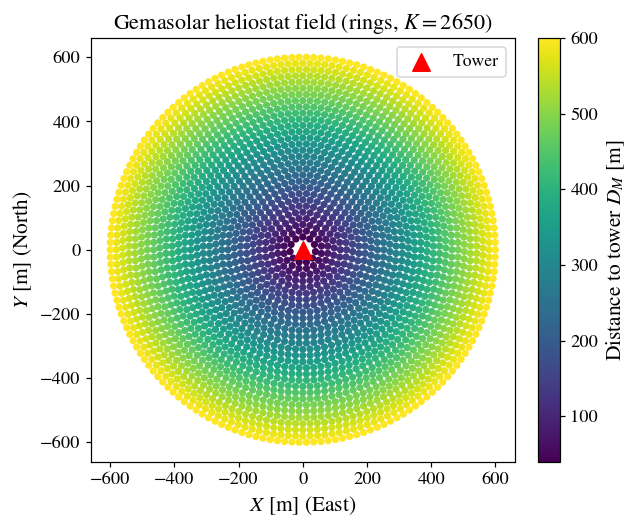

In [5]:
def make_field(layout, K, r_min, r_max):
    if layout == 'phyllotaxis':
        # Fermat/Vogel spiral with golden-angle azimuth (Noone et al. 2012).
        golden = np.pi*(3 - np.sqrt(5))                 # golden angle ~2.39996 rad (137.508 deg)
        k = np.arange(K)
        r = np.sqrt(r_min**2 + (r_max**2 - r_min**2)*(k + 0.5)/K)   # uniform area density
        th = k*golden
        return r*np.cos(th), r*np.sin(th)
    elif layout == 'rings':
        # radial-staggered concentric rings (Gemasolar/campo family), robust to any K.
        n_rings = max(1, int(round(np.sqrt(K/3.0))))    # ~ heuristic ring count
        # distribute K heliostats across rings proportional to ring radius (denser outside)
        radii = np.linspace(r_min, r_max, n_rings)
        weights = radii/radii.sum()
        counts = np.maximum(1, np.round(weights*K).astype(int))
        # fix rounding so counts sum to K
        while counts.sum() > K: counts[np.argmax(counts)] -= 1
        while counts.sum() < K: counts[np.argmin(counts)] += 1
        Xl, Yl = [], []
        for i, (R, c) in enumerate(zip(radii, counts)):
            off = (np.pi/c)*(i % 2)                     # stagger alternating rings
            ang = np.linspace(0, 2*np.pi, c, endpoint=False) + off
            Xl.append(R*np.sin(ang)); Yl.append(R*np.cos(ang))
        return np.concatenate(Xl), np.concatenate(Yl)
    raise ValueError(layout)

X_H, Y_H = make_field(P['field_layout'], K, P['field_r_min_m'], P['field_r_max_m'])
D_M = np.sqrt(X_H**2 + Y_H**2)                            # horizontal distance to tower base
print(f"field: {P['field_layout']}, K={K}, D_M in [{D_M.min():.0f}, {D_M.max():.0f}] m "
      f"(plant={CONFIG['plant']}; full real field = 2650 heliostats)")

fig, ax = plt.subplots(figsize=(5.6, 5))
sc = ax.scatter(X_H, Y_H, s=14, c=D_M, cmap='viridis')
ax.scatter(0, 0, marker='^', s=130, c='red', label='Tower')
plt.colorbar(sc, ax=ax, label=r'Distance to tower $D_{M}$ [m]', fraction=0.046)
ax.set_aspect('equal'); ax.set_xlabel(r'$X$ [m] (East)'); ax.set_ylabel(r'$Y$ [m] (North)')
ax.set_title(f"{CONFIG['plant'].capitalize()} heliostat field ({P['field_layout']}, $K={K}$)")
ax.legend(); plt.savefig('fig3_field.png', dpi=600, bbox_inches='tight'); plt.show()

## 4. Per-heliostat geometry: slant range, incidence, beam spread σ_HF, power P_H

Eqs. (14)–(18): 3-D vector reflection geometry giving each heliostat's slant range
`D`, incidence angle `β`, intercepted power `P_H`, and HFLCAL beam spread `σ_HF`.

HFLCAL is specified slightly differently across the literature on three points, each
resolved here following the original sources (Schwarzbözl et al. 2009; Collado 2010;
Sánchez-González & Santana):

1. **The `cos ω` factor in `σ_HF`** is the incidence of the reflected ray **on the
   receiver surface** — it stretches the footprint on an inclined surface — and *not*
   the heliostat incidence `β`. For the facing aim point on a cylinder the receiver
   normal is horizontal-radial, so `cos ω_rec ≈ (D_M − R_rec)/D`: near-field beams
   arrive steeply and smear out, far-field beams arrive nearly normal. (`β` still
   enters `P_H` through the cosine loss, and the astigmatic terms of Eqs. 17–18.)
2. **Beam quality `σ_bq = 2σ_slope`** is set by the *mirror slope* error, because a
   surface tilted by θ deflects the reflected ray by 2θ. This notebook uses the
   published Gemasolar optical errors — slope 2.6 mrad and tracking 2.1 mrad — giving
   `σ_bq = 5.2 mrad`. Where a plant preset publishes no slope error, `σ_slope ≈ σ_sun`
   is substituted as a fallback; note that the sunshape is a different physical error
   and is only a stand-in for a missing measurement.
3. **Attenuation and blocking.** `f_at` is the standard clear-day atmospheric
   attenuation polynomial in `D` (≈ 2–7 % here; toggled in `CONFIG`). Blocking and
   shadowing between heliostats are neglected (`f_bs = 1`), which is customary at the
   fidelity level of aiming-strategy studies.

In [6]:
helio = np.stack([X_H, Y_H, np.full(K, H_M)], axis=1)
vec = np.array([0,0,H_T])[None,:] - helio
D = np.linalg.norm(vec, axis=1)                  # slant range, Eq.(15)
Tu = vec / D[:,None]
N = S[None,:] + Tu; N /= np.linalg.norm(N, axis=1, keepdims=True)
cos_beta = np.clip(np.einsum('ij,ij->i', N, np.broadcast_to(S,(K,3))), -1, 1)
beta = np.arccos(cos_beta)                       # incidence angle AT THE HELIOSTAT, Eq.(14)
f_focal = D.copy(); d_dim = np.sqrt(A_H); f_bs = 1.0   # f_bs: blocking/shadowing neglected

# atmospheric attenuation heliostat->receiver (clear day, D<=1000 m; Schmitz et al. polynomial)
if CONFIG['use_atm_attenuation']:
    f_at = np.clip(0.99321 - 1.176e-4*D + 1.97e-8*D**2, 0.0, 1.0)
else:
    f_at = np.ones(K)

P_H = I_D*A_H*cos_beta*f_at*eta_ref*f_bs          # Eq.(14)
H_t_img = d_dim*np.abs(D/f_focal - cos_beta)      # Eq.(18)
w_s_img = d_dim*np.abs(D/f_focal*cos_beta - 1)
sigma_ast = np.sqrt(0.5*(H_t_img**2 + w_s_img**2))/(4*D)   # Eq.(17)
if sigma_slope is not None:
    sigma_bq = 2*sigma_slope   # HFLCAL beam quality: a mirror tilted by theta deflects the ray by 2*theta
else:
    sigma_bq = 2*sigma_sun     # STAND-IN when the preset publishes no slope error (see note above)

# HFLCAL's cos(omega) is the incidence of the REFLECTED RAY ON THE RECEIVER SURFACE
# (footprint elongation on an inclined surface), not the heliostat incidence beta.
# For the facing aim point on the cylinder the receiver normal is horizontal-radial, so
# cos(omega_rec) ~ horizontal distance / slant range:
cos_w_rec = np.clip((D_M - R_rec)/D, 0.05, 1.0)
sigma_HF = np.sqrt(D**2*(sigma_sun**2 + sigma_bq**2 + sigma_ast**2 + sigma_t**2)/cos_w_rec)

print(f"sigma_sun={sigma_sun*1e3:.2f} mrad, sigma_bq=2*sigma_slope={sigma_bq*1e3:.2f} mrad, "
      f"sigma_t={sigma_t*1e3:.2f} mrad")
print(f"D:         [{D.min():.1f}, {D.max():.1f}] m   |   f_at: [{f_at.min():.3f}, {f_at.max():.3f}]")
print(f"beta:      [{np.degrees(beta).min():.2f}, {np.degrees(beta).max():.2f}] deg (at heliostat)")
print(f"cos_w_rec: [{cos_w_rec.min():.3f}, {cos_w_rec.max():.3f}] (at receiver; near-field beams arrive steeply)")
print(f"sigma_HF:  [{sigma_HF.min():.3f}, {sigma_HF.max():.3f}] m")
print(f"P_H:      [{P_H.min():.3f}, {P_H.max():.3f}] kW")

sigma_sun=2.73 mrad, sigma_bq=2*sigma_slope=5.20 mrad, sigma_t=2.10 mrad
D:         [121.8, 610.9] m   |   f_at: [0.929, 0.979]
beta:      [1.80, 58.55] deg (at heliostat)
cos_w_rec: [0.294, 0.975] (at receiver; near-field beams arrive steeply)
sigma_HF:  [1.189, 4.073] m
P_H:      [50.060, 100.915] kW


## 5. Unwrapped-cylinder receiver, nominal aiming, and nominal flux

The cylindrical receiver is unwrapped along its vertical centerline (manuscript
Sec. 3.2): the horizontal pixel axis is the **circumference** (width = π·D ≈ 26.7 m
for Gemasolar's 8.5 m diameter), the vertical axis the receiver height. Two features
make this a faithful surround-field model rather than a flat-receiver approximation:

1. **Periodicity.** The surface wraps, so circumferential distances are measured the
   shorter way around (`circ_dx`); a heliostat aiming near the seam contributes to
   both edges of the unwrapped map. The far side of the cylinder stays dark
   automatically, because the wrapped distance to it is ≈ half a circumference ≫ σ_HF.
2. **Facing-azimuth aiming with an aiming factor.** Each heliostat's nominal aim
   point sits at the circumferential position facing it (its azimuth → arc length).
   Vertically, the default `aimfactor` scheme is a realistic **AFD-feasible aiming
   strategy** of the kind used operationally (Vant-Hull 2002; Sánchez-González et al.
   2017): aim points alternate above and below the equator at a distance from the
   receiver edge proportional to each heliostat's beam radius,
   `|y| = H_rec/2 − f_aim·σ_HF_k`, with `f_aim` tuned by bisection so that the nominal
   peak sits at `nominal_peak_target × F_max` (default 0.95 — an operating margin, as
   in practice). Starting from a *feasible* nominal matters: it ensures the
   thermal-limit violation analyzed later is produced by the structural drift, not
   assumed into the baseline aiming.

Because each HFLCAL spot is a **separable Gaussian**,
`exp(−(Δx²+Δy²)/2σ²) = exp(−Δx²/2σ²)·exp(−Δy²/2σ²)`, a full flux evaluation reduces
to a single `(n_v×K) @ (K×n_h)` matrix product over precomputed 1-D profiles — about
100× faster than looping over heliostats and pixels, and the basis of the fast QP
assembly in Sec. 8.

> **Curvature.** HFLCAL places a single 2-D Gaussian on the unwrapped surface and
> ignores distortion of the footprint by the cylinder's curvature. That is the
> fidelity level of the model; for σ_HF comparable to the receiver radius it is a
> mild approximation.

aiming-factor nominal: f_aim = 1.527 (|y| = H/2 - f_aim*sigma_HF, alternating), tuned to peak = 0.95 x AFD
nominal flux: max=950.0, mean=647.7 kW/m^2
intercepted ~ 181596 kW of 201513 kW delivered (interception 90.12%)
single-heliostat check: analytic peak=8.0692, grid max=8.0450


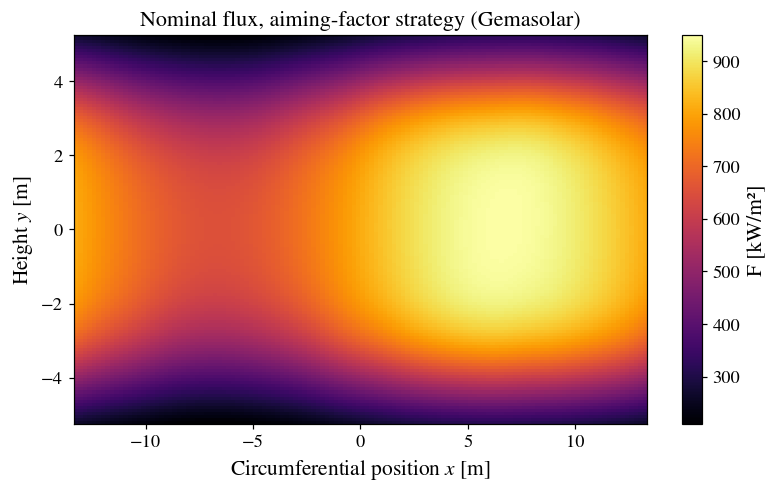

3-D render saved to fig5_nominal_flux_3d.png (not displayed -- paper mode)


In [7]:
# --- unwrapped-cylinder pixel grid: x = circumferential arc [-C/2, C/2], y = height ---
x_c = 0.5*(np.linspace(-C_circ/2, C_circ/2, n_h+1)[:-1] + np.linspace(-C_circ/2, C_circ/2, n_h+1)[1:])
y_c = 0.5*(np.linspace(-H_rec/2, H_rec/2, n_v+1)[:-1] + np.linspace(-H_rec/2, H_rec/2, n_v+1)[1:])
Xg, Yg = np.meshgrid(x_c, y_c)
xpix = Xg.ravel(); ypix = Yg.ravel(); n_pixels = xpix.size
pixel_area = (C_circ/n_h)*(H_rec/n_v)

def circ_dx(a, b):
    """Signed shortest circumferential distance a-b on a cylinder of circumference C_circ."""
    d = a - b
    return d - C_circ*np.round(d/C_circ)

# --- heliostat azimuth -> facing circumferential coordinate on the receiver ---
theta_h = np.arctan2(Y_H, X_H)            # heliostat azimuth [rad]
x_face = R_rec*theta_h                      # arc-length coordinate of the facing point
x_face = circ_dx(x_face, 0.0)              # wrap into [-C/2, C/2]

_pref   = P_H/(2*np.pi*sigma_HF**2)            # per-heliostat Gaussian prefactor (precomputed once)
_inv2s2 = 1.0/(2*sigma_HF**2)

def gauss_profiles(x0, y0):
    """Separable 1-D Gaussian factors of every heliostat's HFLCAL spot on the pixel grid:
    exp(-(dx^2+dy^2)/2s^2) = exp(-dx^2/2s^2)*exp(-dy^2/2s^2). Returns Gx (K,n_h), Gy (K,n_v)
    and the signed distances; all flux/sensitivity assembly reduces to small matmuls."""
    dxc = circ_dx(x_c[None, :], x0[:, None])          # (K, n_h), wrapped
    dyc = y_c[None, :] - y0[:, None]                  # (K, n_v)
    Gx = np.exp(-(dxc*dxc)*_inv2s2[:, None])
    Gy = np.exp(-(dyc*dyc)*_inv2s2[:, None])
    return Gx, Gy, dxc, dyc

def flux_map(x0, y0):
    """True nonlinear HFLCAL total flux on the unwrapped cylinder (Eq. 4-5), with
    circumferential periodicity. Separable form: F(v,h) = sum_k pref_k*Gy[k,v]*Gx[k,h]
    is one (n_v x K)@(K x n_h) matmul over 1-D profiles -- ~100x faster than the
    per-heliostat pixel loop. Flattened (n_pixels,)."""
    Gx, Gy, _, _ = gauss_profiles(x0, y0)
    return ((Gy*_pref[:, None]).T @ Gx).ravel()

def interception(F):
    """Fraction of the power delivered by the field that lands on the receiver."""
    return float(F.sum()*pixel_area/P_H.sum())

# --- nominal aim points (CONFIG['aim_scheme']): GIVEN upstream of Problem 1 ---
if CONFIG['aim_scheme'] == 'center':
    x0_t = x_face.copy(); y0_t = np.zeros(K)                  # facing azimuth, equator
elif CONFIG['aim_scheme'] == 'vertical':
    x0_t = x_face.copy()                                       # facing azimuth
    y0_t = np.linspace(-H_rec/2*0.7, H_rec/2*0.7, K)          # Vant-Hull-style vertical spread
elif CONFIG['aim_scheme'] == 'spread':                         # legacy: mild equatorial stagger
    x0_t = x_face.copy()
    y0_t = (np.arange(K) % 5 - 2)/2.0 * (H_rec/2*0.5)/2.0
else:  # 'aimfactor' -- realistic AFD-feasible aiming strategy (default)
    # Aiming-factor strategy (Vant-Hull 2002; Sanchez-Gonzalez et al. 2017): aim points
    # alternate above/below the equator at a distance from the receiver edge proportional
    # to each heliostat's beam radius, |y| = H_rec/2 - f_aim*sigma_HF_k (floored at the
    # equator). Small f_aim -> aims near the edges (flat but spills); large f_aim -> aims
    # near the equator (safe from spillage but peaked). f_aim is bisected so the NOMINAL
    # peak sits at nominal_peak_target*F_max: the plant's own aiming strategy is
    # AFD-feasible by design, as in practice.
    x0_t = x_face.copy()
    s_k = np.where(np.arange(K) % 2 == 0, 1.0, -1.0)           # alternate up/down
    F_cap_target = CONFIG['nominal_peak_target']*(P['F_max_kw'] if P['F_max_mode'] == 'absolute'
                                                  else np.inf)
    def _aim_y(f):
        return s_k*np.maximum(H_rec/2.0 - f*sigma_HF, 0.0)
    lo, hi = 0.3, 4.0
    for _ in range(40):
        mid = 0.5*(lo + hi)
        if flux_map(x0_t, _aim_y(mid)).max() > F_cap_target: hi = mid
        else: lo = mid
    f_aim = 0.5*(lo + hi)
    y0_t = _aim_y(f_aim)
    print(f"aiming-factor nominal: f_aim = {f_aim:.3f} (|y| = H/2 - f_aim*sigma_HF, alternating), "
          f"tuned to peak = {CONFIG['nominal_peak_target']:.2f} x AFD")

F_nominal = flux_map(x0_t, y0_t)
print(f"nominal flux: max={F_nominal.max():.1f}, mean={F_nominal.mean():.1f} kW/m^2")
print(f"intercepted ~ {F_nominal.sum()*pixel_area:.0f} kW of {P_H.sum():.0f} kW delivered "
      f"(interception {100*interception(F_nominal):.2f}%)")

# sanity: single-heliostat peak vs closed form
kt = 0
F1 = (P_H[kt]/(2*np.pi*sigma_HF[kt]**2))*np.exp(
    -(circ_dx(xpix, x0_t[kt])**2 + (ypix-y0_t[kt])**2)/(2*sigma_HF[kt]**2))
print(f"single-heliostat check: analytic peak={P_H[kt]/(2*np.pi*sigma_HF[kt]**2):.4f}, "
      f"grid max={F1.max():.4f}")

# ---- 3-D visualization helpers (shared with the comparison figure) ----
from matplotlib import colormaps, colors as mcolors, cm

def receiver_mesh(F, R_draw=None, z_center=0.0, z_scale=1.0):
    # Map the unwrapped (n_v x n_h) flux onto the 3-D cylinder. Unwrapped x = R*theta
    # with theta = atan2(Y, X), so the render shares the field's East-North frame
    # (the bright northern lobe sits at theta = 90 deg = +Y/North).
    R = (R_rec if R_draw is None else R_draw)
    th = np.append(x_c, x_c[0] + C_circ)/R_rec          # close the periodic seam
    zz = y_c*z_scale + z_center
    TH, ZZ = np.meshgrid(th, zz)
    Fg = F.reshape(n_v, n_h)
    Fg = np.concatenate([Fg, Fg[:, :1]], axis=1)
    return R*np.cos(TH), R*np.sin(TH), ZZ, Fg

def draw_flux_cylinder(ax, F, norm, R_draw=None, z_center=0.0, z_scale=1.0):
    X3, Y3, Z3, Fg = receiver_mesh(F, R_draw, z_center, z_scale)
    ax.plot_surface(X3, Y3, Z3, facecolors=colormaps['inferno'](norm(Fg)),
                    rcount=Fg.shape[0], ccount=Fg.shape[1],
                    shade=False, linewidth=0, antialiased=False)

def hot_azim_deg(F):
    # Camera azimuth facing the peak-flux meridian, computed FROM THE DATA:
    # a 3-D view hides half the surface, so each render faces its own hot spot.
    return float(np.degrees(xpix[int(np.argmax(F))]/R_rec))

# ---- 2-D unwrapped map: THE manuscript figure (displayed) ----
fig2 = plt.figure(figsize=(8.4, 4.6)); ax2 = fig2.add_subplot()
im2 = ax2.imshow(F_nominal.reshape(n_v, n_h), extent=[-C_circ/2, C_circ/2, -H_rec/2, H_rec/2],
                 origin='lower', cmap='inferno', aspect='auto')
fig2.colorbar(im2, ax=ax2, label='F [kW/m²]')
ax2.set_xlabel('Circumferential position $x$ [m]'); ax2.set_ylabel('Height $y$ [m]')
ax2.set_title(f'Nominal flux, aiming-factor strategy ({CONFIG["plant"].capitalize()})')
fig2.savefig('fig5_nominal_flux.png', dpi=600, bbox_inches='tight'); plt.show()

# ---- 3-D figure: plant context (left) + receiver flux close-up (right) -- SAVED, not shown ----
mag = CONFIG['plot3d_receiver_mag']
norm_n = mcolors.Normalize(vmin=0.0, vmax=float(F_nominal.max()))
fig = plt.figure(figsize=(13.2, 5.8))

axL = fig.add_subplot(1, 2, 1, projection='3d')
axL.scatter(X_H, Y_H, np.zeros(K), s=4, c=D_M, cmap='viridis', alpha=0.5, linewidths=0)
tt = np.linspace(0, 2*np.pi, 60); tz = np.array([0.0, H_T - mag*H_rec/2])
TT, TZ = np.meshgrid(tt, tz)
axL.plot_surface(8*np.cos(TT), 8*np.sin(TT), TZ, color='0.55', shade=True,
                 linewidth=0, antialiased=False)
draw_flux_cylinder(axL, F_nominal, norm_n, R_draw=mag*R_rec, z_center=H_T, z_scale=mag)
for k in np.linspace(0, K - 1, 14).astype(int):         # sample reflected rays
    th_a = x0_t[k]/R_rec
    axL.plot([X_H[k], mag*R_rec*np.cos(th_a)], [Y_H[k], mag*R_rec*np.sin(th_a)],
             [H_M, H_T + mag*y0_t[k]], color='gold', lw=0.8, alpha=0.6)
axL.text(0, 1.12*D_M.max(), 0, 'N', fontsize=13, ha='center')
axL.set_box_aspect((1, 1, 0.42)); axL.view_init(elev=16, azim=-58)
axL.set_axis_off()
axL.set_title(f'Plant context (receiver drawn {mag}x for visibility)', fontsize=11.5)

axR = fig.add_subplot(1, 2, 2, projection='3d')
draw_flux_cylinder(axR, F_nominal, norm_n)
azn = hot_azim_deg(F_nominal)
axR.view_init(elev=14, azim=azn)
axR.set_box_aspect((1, 1, H_rec/D_rec)); axR.set_axis_off()
axR.set_title('Receiver close-up (true proportions)' + chr(10)
              + f'peak {F_nominal.max():.0f} kW/m²  (view: hot-spot azimuth {azn:.0f}°)',
              fontsize=11.5)

sm = cm.ScalarMappable(norm=norm_n, cmap='inferno'); sm.set_array([])
fig.colorbar(sm, ax=fig.axes, shrink=0.62, pad=0.02, label='F [kW/m²]')
fig.suptitle(f'{CONFIG["plant"].capitalize()}: nominal flux on the cylindrical receiver',
             y=0.99, fontsize=13)
fig.savefig('fig5_nominal_flux_3d.png', dpi=600, bbox_inches='tight'); plt.close(fig)
print("3-D render saved to fig5_nominal_flux_3d.png (not displayed -- paper mode)")

## 6. Structural misalignment Δmech (Eq. 6)

Eq. (6) maps an angular misalignment — a slow structural drift such as foundation
settling or soil erosion — to an aim-point displacement on the receiver; on the
unwrapped cylinder the dominant effect is a **circumferential** shift. Heliostats on
opposite sides of the field shift their aim points in **opposing rotational
directions**, so the aim points **converge** toward one meridian and pile flux into a
hot spot. This convergent pattern is the worst case for a given misalignment
magnitude, and it is the deterministic perturbation used throughout the comparison.

**Δmech is a residual, not the raw structural error.** A literal 1° structural error
maps to ≈ 2–11 m of displacement over this field's slant ranges — larger than the
receiver itself, larger than the ±`delta_max` correction box, and larger than the beam
width σ_HF, hence outside the validity of any linearized correction. That degree-level
figure describes an *uncalibrated* heliostat; periodic calibration and tracking bring
it down to a few milliradians, and it is this **residual** that Phase 2 corrects.
Two residual models are available via `CONFIG['mis_model']`: `'displacement'`
(default) applies the same residual displacement to every heliostat, while `'angle'`
applies the same residual beam angle so that displacement scales with slant range —
the literal form of Eq. (6), in which farther heliostats shift more.

**Two angle conventions, both reported.** A mirror tilted by θ deflects the reflected
beam by 2θ, so a displacement can be quoted as either a beam deviation or half that
as a mirror tilt. To keep this unambiguous, the cell prints the residual as a
displacement in metres *and* as both angles: the beam-angle equivalent `atan(d/D)`
and the mirror-tilt equivalent `½·atan(d/D)`.

In [8]:
if CONFIG['mis_model'] == 'angle':
    ang_in = CONFIG['mis_residual_angle_mrad']*1e-3
    Dmech_k = D*np.tan(ang_in)                      # Eq. (6): same residual BEAM angle for all
else:
    Dmech_k = np.full(K, CONFIG['mis_displacement_scale_m'])   # same residual displacement for all
Dmech_mag = float(Dmech_k.mean())                   # scale used by the Sec. 11 sweep

# Fig. 6 opposing-rotation convergence: +90deg and -90deg heliostats both shift toward x=0.
dmech_x = -Dmech_k*np.sin(theta_h)                  # circumferential, converging
dmech_y =  Dmech_k*np.cos(theta_h)                  # vertical component
x0_mis = x0_t + dmech_x
y0_mis = y0_t + dmech_y

# angular equivalents over the slant-range span: beam angle atan(d/D); mirror tilt = half of it
ang_beam = np.arctan(Dmech_k/D)                     # what the reflected RAY does [rad]
ang_mirr = 0.5*ang_beam                             # what the STRUCTURE tilted [rad] (Eq. 6 factor of 2)
F_perturbed = flux_map(x0_mis, y0_mis)
print(f"mis_model='{CONFIG['mis_model']}': Delta_mech = {Dmech_k.min():.2f}-{Dmech_k.max():.2f} m "
      f"residual per heliostat (mean {Dmech_mag:.2f} m)")
print(f"  beam-angle equivalent  : {ang_beam.min()*1e3:.2f}-{ang_beam.max()*1e3:.2f} mrad "
      f"({np.degrees(ang_beam).min():.3f}-{np.degrees(ang_beam).max():.3f} deg) over D={D.min():.0f}-{D.max():.0f} m")
print(f"  mirror-tilt equivalent : {ang_mirr.min()*1e3:.2f}-{ang_mirr.max()*1e3:.2f} mrad "
      f"(beam deflection = 2 x mirror tilt -- state Eq. 6 with this factor)")
print(f"correction box +/-{delta_x_max:.2f} m,  beam width sigma_HF ~ {sigma_HF.min():.1f}-{sigma_HF.max():.1f} m")
print(f"perturbed flux: max={F_perturbed.max():.1f}, mean={F_perturbed.mean():.1f} kW/m^2 "
      f"(vs nominal max={F_nominal.max():.1f})")

mis_model='displacement': Delta_mech = 1.00-1.00 m residual per heliostat (mean 1.00 m)
  beam-angle equivalent  : 1.64-8.21 mrad (0.094-0.471 deg) over D=122-611 m
  mirror-tilt equivalent : 0.82-4.11 mrad (beam deflection = 2 x mirror tilt -- state Eq. 6 with this factor)
correction box +/-1.00 m,  beam width sigma_HF ~ 1.2-4.1 m
perturbed flux: max=1039.1, mean=639.9 kW/m^2 (vs nominal max=950.0)


## 7. Linearization (Eqs. 7–11) and finite-difference validation

A first-order Taylor expansion of each heliostat's flux about its *misaligned* aim
point gives the linear model `F̃(z) = F0 + Ax·δx + Ay·δy` that the QP optimizes. The
sensitivity of pixel *p* to a circumferential shift of heliostat *k* is

  `A_x[p,k] = F0_pk · (xₚ − x̄_k) / σ_k²`   (and analogously for `A_y`),

which is **positive when the pixel lies on the +x side of the aim point**: moving an
aim point toward a pixel increases the flux there. Expanding about the misaligned
configuration — rather than the nominal one — is what makes the correction variables
enter linearly while keeping the expansion point close to the true operating state.

Because each spot is a separable Gaussian, every column of `A_x`/`A_y` factors into
1-D profiles (`A_x[:,k] = gy_k ⊗ gxd_k`), so the full `n_pixels × 2K` matrix is never
materialized: Sec. 8 assembles `AᵀA`, `Aᵀb` and the flux-cap rows directly from the
factors.

The sign and scale of these coefficients are the single most error-prone part of the
derivation, so the cell **validates them against numerical gradients** of the true
nonlinear flux at heliostats sampled across the field (inner, middle, outer). Target:
relative error of order `1e-3` with 100 % sign agreement in both directions.

In [9]:
def build_sensitivity(x0m, y0m):
    """Factored linearized flux model on the unwrapped cylinder: F_tilde(z) = F0 + Ax@dx + Ay@dy
    with Ax[:,k] = gy_k (x) gxdp_k and Ay[:,k] = gyd_k (x) gxp_k (outer products of 1-D
    profiles; Eq. 7-11 with the validated sign + C factor, prefactor folded into the x-side).
    Uses the wrapped circumferential distance. Returns F0 + the four (K x n) factor matrices;
    the n_pixels x 2K matrix A is never materialized (see Sec. 8 assembly)."""
    Gx, Gy, dxc, dyc = gauss_profiles(x0m, y0m)
    inv_s2 = (2*_inv2s2)[:, None]                     # = 1/sigma_k^2
    Gxp  = _pref[:, None]*Gx
    Gxdp = Gxp*dxc*inv_s2                             # d/d(dx) profile, wrapped
    Gyd  = Gy*dyc*inv_s2
    F0 = (Gy.T @ Gxp).ravel()
    return F0, Gy, Gyd, Gxp, Gxdp

def sens_cols(S_, k):
    """Materialize A_x[:,k], A_y[:,k] from the factors (validation/diagnostics only)."""
    _, Gy, Gyd, Gxp, Gxdp = S_
    return (np.outer(Gy[k],  Gxdp[k]).ravel(),
            np.outer(Gyd[k], Gxp[k] ).ravel())

S_mis = build_sensitivity(x0_mis, y0_mis)
F0 = S_mis[0]

# ---- finite-difference validation (the decisive correctness check) ----
eps = 1e-4
def fd_check(kp):
    Axk, Ayk = sens_cols(S_mis, kp)
    xp = x0_mis.copy(); xp[kp] += eps
    fdx = (flux_map(xp, y0_mis) - F_perturbed)/eps
    yp = y0_mis.copy(); yp[kp] += eps
    fdy = (flux_map(x0_mis, yp) - F_perturbed)/eps
    mx = np.abs(Axk) > 1e-6; my = np.abs(Ayk) > 1e-6
    return (np.abs(fdx[mx]-Axk[mx])/np.abs(Axk[mx])).max(), \
           np.mean(np.sign(fdx[mx])==np.sign(Axk[mx]))*100, \
           (np.abs(fdy[my]-Ayk[my])/np.abs(Ayk[my])).max(), \
           np.mean(np.sign(fdy[my])==np.sign(Ayk[my]))*100

print("finite-diff vs analytic sensitivity (3 sample heliostats):")
print(f"{'helio':>6}{'dx rel-err':>13}{'dx sign%':>10}{'dy rel-err':>13}{'dy sign%':>10}")
for kp in sorted({min(10, K-1), K//2, max(0, K-5)}):
    ex, sx, ey, sy = fd_check(kp)
    print(f"{kp:>6}{ex:>13.2e}{sx:>10.1f}{ey:>13.2e}{sy:>10.1f}")
print("\n==> rel-err ~1e-3 and 100% sign agreement confirms the coefficients are correct.")

finite-diff vs analytic sensitivity (3 sample heliostats):
 helio   dx rel-err  dx sign%   dy rel-err  dy sign%
    10     2.79e-03     100.0     2.75e-03     100.0


  1325     1.30e-03     100.0     4.65e-03     100.0


  2645     9.75e-04     100.0     1.48e-03     100.0

==> rel-err ~1e-3 and 100% sign agreement confirms the coefficients are correct.


## 8. Convex QP (Eq. 12) — flux flattening under the AFD limit

  minimize ‖F̃(z) − F_ref‖₂²  subject to  F̃ ≤ F_max,  |δx_k| ≤ δx_max,  |δy_k| ≤ δy_max

The objective drives the receiver flux toward a **uniform reference** `F_ref` (a flat
profile at the mean intercepted level), making this a flux-*flattening* problem, while
the hard constraint `F̃ ≤ F_max` enforces the **allowable flux density** — for
Gemasolar the real AFD of ≈ 1000 kW/m² (Sánchez-González et al. 2017). The objective
is convex quadratic and every constraint is linear, so the program is a convex QP
whose solution is a certified global optimum of the linearized problem.

**Aim points stay on the receiver.** Besides the correction box, each corrected aim
point is constrained vertically to the receiver surface:
`|ȳ_k + δy_k| ≤ H_rec/2 − aim_margin·σ_HF` — per-heliostat linear bounds, so the
problem remains a QP. The circumferential direction needs no such bound because the
cylinder is periodic. Without it, a wide box would let the optimizer "reduce" peak
flux by pushing beams off the edge of the receiver, which is spillage rather than
flattening.

**How it is solved fast.** All three steps below were validated to give the same
optimum as a dense, straightforwardly-canonicalized reference implementation:

1. *Factored normal equations.* Each K×K block of `H = AᵀA` is a Hadamard product of
   two small Gram matrices of the 1-D profiles (e.g. `H_xx = (Gy Gyᵀ) ∘ (Gxd Gxdᵀ)`),
   so `H` and `g = Aᵀb` assemble from a handful of `(K×n)` matrix products without
   ever forming `A`.
2. *Direct solver call.* The QP `min zᵀHz − 2gᵀz` is handed to CLARABEL as sparse
   data, skipping modeling-layer canonicalization — a substantial overhead at
   `2K = 5300` variables.
3. *Thinned cap rows with cutting-plane refinement.* Flux-cap rows are first imposed
   on a `cap_stride`-subsampled grid of the pixels that could approach the limit
   (`F0 > cap_prune·F_max`); since the pixel pitch is much finer than σ_HF, adjacent
   rows are near-duplicates. After each solve the cap is re-checked on **all**
   candidate pixels and any violated rows are added and the QP re-solved, so the
   constraint is enforced exactly on the linear model — in practice after one round.

**Uniformity metric.** Uniformity is reported as the **coefficient of variation**
`CV = std(F)/mean(F)` over the illuminated receiver: 0 is perfectly flat, larger is
more peaked. CV is intrinsic — it does not depend on the choice of reference level —
so it compares methods on equal footing. Lower is better.

**Linearization validity.** The QP optimizes a first-order model, and corrections as
large as `delta_max` can approach the smallest beam widths, where a Taylor step is no
longer locally exact. Two safeguards: every reported metric is evaluated on the
**true nonlinear flux** at the computed corrections, and the cell prints both the
model-vs-true gap and the largest step in units of σ_HF. The flux cap is likewise
re-checked on the true flux, with a warning if it is exceeded. Should that gap ever
become material, re-linearizing about the solution (sequential convex programming
with a trust region) is the standard tightening.

In [10]:
# ---- reference flux + thermal limit F_max (from plant preset) ----
F_ref = np.full(n_pixels, F_nominal.mean())                # uniform flattening target, Eq.(12) text
if P['F_max_mode'] == 'absolute':
    F_max = P['F_max_kw']                                   # real AFD (Gemasolar ~1000 kW/m^2)
    binds = '(nominal peak %.0f vs AFD %.0f -> %s)' % (
        F_nominal.max(), F_max, 'cap binds' if F_nominal.max() > 0.6*F_max else 'cap loose at this K')
else:
    F_max = P['F_max_factor']*F_nominal.max()               # relative cap fallback
    binds = '(relative cap = %.2f x nominal peak)' % P['F_max_factor']
print(f"F_ref level = {F_ref[0]:.1f} kW/m^2 | F_max = {F_max:.0f} kW/m^2  {binds}")

def _qp_terms(S_, b):
    """H = A^T A and g = A^T b from the separable factors: each K x K block of H is a
    Hadamard product of two small Gram matrices -- A itself is never materialized."""
    _, Gy, Gyd, Gxp, Gxdp = S_
    H = np.empty((2*K, 2*K))
    H[:K, :K] = (Gy  @ Gy.T )*(Gxdp @ Gxdp.T)
    H[K:, K:] = (Gyd @ Gyd.T)*(Gxp  @ Gxp.T )
    Hxy       = (Gy  @ Gyd.T)*(Gxdp @ Gxp.T )
    H[:K, K:] = Hxy; H[K:, :K] = Hxy.T
    B = b.reshape(n_v, n_h)
    g = np.concatenate([((Gy  @ B)*Gxdp).sum(1), ((Gyd @ B)*Gxp).sum(1)])
    return H, g

def _cap_rows(S_, ps):
    """Rows of A for pixel indices ps (flux-cap constraints), from the factors."""
    _, Gy, Gyd, Gxp, Gxdp = S_
    vs, hs = ps // n_h, ps % n_h
    return np.hstack([(Gy[:, vs]*Gxdp[:, hs]).T, (Gyd[:, vs]*Gxp[:, hs]).T])

def _lin_flux(S_, z):
    """Linear-model flux prediction F0 + A@z on ALL pixels, via two matmuls."""
    F0_, Gy, Gyd, Gxp, Gxdp = S_
    return F0_ + (Gy.T @ (z[:K, None]*Gxdp) + Gyd.T @ (z[K:, None]*Gxp)).ravel()

def _clarabel_qp(H, g, lb, ub, Acap, rcap):
    """min z'Hz - 2g'z  s.t. lb <= z <= ub, Acap z <= rcap. CLARABEL called directly
    (skipping cvxpy canonicalization, a large overhead at 2K = 5300)."""
    n = 2*K
    Pq = sp.triu(sp.csc_matrix(2.0*H), format='csc')
    Ieye = sp.eye(n, format='csc')
    blocks, rhs = [Ieye, -Ieye], [ub, -lb]
    if Acap is not None and Acap.shape[0]:
        blocks.append(sp.csc_matrix(Acap)); rhs.append(rcap)
    Acon = sp.vstack(blocks, format='csc')
    st = clarabel.DefaultSettings(); st.verbose = False
    if CONFIG['qp_tol'] is not None:
        st.tol_gap_rel = st.tol_gap_abs = st.tol_feas = CONFIG['qp_tol']
    sol = clarabel.DefaultSolver(Pq, -2.0*g, Acon, np.concatenate(rhs),
                                 [clarabel.NonnegativeConeT(Acon.shape[0])], st).solve()
    ok = str(sol.status) in ('Solved', 'AlmostSolved')
    return (np.asarray(sol.x) if ok else None), str(sol.status)

def solve_qp(x0m, y0m, F_ref, F_max):
    """Build the linearized model around (x0m,y0m) and solve the convex QP (Eq. 12).
    Constraints: (i) correction box |dz| <= delta_max; (ii) corrected aim points on the
    receiver vertically (periodic circumferentially, so no x bound); (iii) flux cap on a
    cap_stride-thinned set of the F0 > cap_prune*F_max pixels, with violated candidates
    added back and the QP re-solved (cutting plane) until the linear cap holds on ALL
    candidates. Metrics are evaluated on the TRUE nonlinear flux. Returns status, timing,
    corrections, true-flux metrics, diagnostics."""
    t0 = time.time()
    S_ = build_sensitivity(x0m, y0m)
    F0_ = S_[0]
    H, g = _qp_terms(S_, F_ref - F0_)
    # per-heliostat bounds: x = pure box (periodic surface); y = box AND on-receiver
    y_edge = H_rec/2.0 - CONFIG['aim_margin_sigma']*sigma_HF
    lb = np.concatenate([np.full(K, -delta_x_max), np.maximum(-delta_y_max, -y_edge - y0m)])
    ub = np.concatenate([np.full(K,  delta_x_max), np.minimum( delta_y_max,  y_edge - y0m)])
    off = lb[K:] > ub[K:]                            # aim so far off the box can't return it:
    if off.any():                                    # pin dy to pull toward the receiver
        pin = np.where(y0m[off] > 0, -delta_y_max, delta_y_max)
        lb[K:][off] = ub[K:][off] = pin
    cap_mask = F0_ > CONFIG['cap_prune']*F_max       # candidate cap pixels
    s_ = max(1, int(CONFIG['cap_stride']))
    thin = np.zeros((n_v, n_h), dtype=bool)
    thin[::s_, ::s_] = cap_mask.reshape(n_v, n_h)[::s_, ::s_]
    ps = np.where(thin.ravel())[0]
    zc, status, F_lin = None, 'unsolved', None
    for rounds in range(1, 4):                       # cutting-plane loop (1 round is typical)
        Acap = _cap_rows(S_, ps) if ps.size else None
        rcap = (F_max - F0_)[ps] if ps.size else None
        z, status = _clarabel_qp(H, g, lb, ub, Acap, rcap)
        if z is None:
            return dict(status=status, time=time.time()-t0, dx=None, n_cap=int(ps.size))
        zc = np.clip(z, lb, ub)
        F_lin = _lin_flux(S_, zc)
        viol = np.where(cap_mask & (F_lin > F_max*(1 + 1e-6)))[0]
        new = np.setdiff1d(viol, ps)
        if new.size == 0:
            break
        ps = np.union1d(ps, new)                     # add violated rows, re-solve
    dt = time.time()-t0
    dxo, dyo = zc[:K], zc[K:]
    Fc = flux_map(x0m+dxo, y0m+dyo)                  # evaluate with TRUE nonlinear flux
    lin_gap = float(np.linalg.norm(F_lin - Fc)/np.linalg.norm(Fc))
    step_sigma = float(max(np.abs(dxo).max(), np.abs(dyo).max()) / sigma_HF.min()) if K else 0.0
    cap_exceed = float(max(0.0, Fc.max() - F_max)) if np.isfinite(F_max) else 0.0
    aim_y_max = float(np.abs(y0m + dyo).max())        # on-receiver check (<= H_rec/2)
    return dict(status=status, time=dt, dx=dxo, dy=dyo,
                obj=float(np.sum((F_lin - F_ref)**2)), n_cap=int(ps.size), rounds=rounds,
                F_true=Fc, J_true=float(np.sum((Fc-F_ref)**2)), peak=float(Fc.max()),
                lin_gap=lin_gap, step_sigma=step_sigma, cap_exceed=cap_exceed,
                aim_y_max=aim_y_max)

# Uniformity = coefficient of variation over the illuminated receiver (intrinsic; lower = flatter).
# The illuminated mask is fixed from the nominal flux so every method is scored on the same pixels.
illum_mask = F_nominal > 0.05*F_nominal.max()
def uniformity(F):
    Fi = F[illum_mask]
    return float(np.std(Fi)/np.mean(Fi))

qp = solve_qp(x0_mis, y0_mis, F_ref, F_max)
qp_time = qp['time']
if qp['dx'] is None:
    print(f"QP [CLARABEL direct]: status={qp['status']} (no solution) -- "
          f"the +-{delta_x_max} m box cannot satisfy F_max given Delta_mech. "
          f"Downstream uses no-correction.")
    F_qp_true = F_perturbed
else:
    F_qp_true = qp['F_true']
    print(f"QP [CLARABEL direct]: status={qp['status']}, obj={qp['obj']:.4e}, "
          f"time={qp_time:.2f}s, cap rows={qp['n_cap']} ({qp['rounds']} cutting-plane round(s))")
    print(f"QP-corrected (true flux): CV={uniformity(F_qp_true):.4f}, peak={F_qp_true.max():.1f}")
    print(f"linearization check: model-vs-true flux gap = {100*qp['lin_gap']:.2f}%  "
          f"(max step = {qp['step_sigma']:.2f} x smallest sigma_HF)")
    print(f"aim bound check: max |y_aim| = {qp['aim_y_max']:.2f} m  (receiver half-height {H_rec/2:.2f} m)")
    if qp['cap_exceed'] > 0:
        print(f"WARNING: true flux exceeds F_max by {qp['cap_exceed']:.1f} kW/m^2 -- the cap is "
              f"enforced on the linearized model; re-linearize about the solution (SLP) to tighten.")

F_ref level = 647.7 kW/m^2 | F_max = 1000 kW/m^2  (nominal peak 950 vs AFD 1000 -> cap binds)


QP [CLARABEL direct]: status=Solved, obj=2.0203e+08, time=142.24s, cap rows=1071 (1 cutting-plane round(s))
QP-corrected (true flux): CV=0.1493, peak=720.5
linearization check: model-vs-true flux gap = 5.42%  (max step = 0.84 x smallest sigma_HF)
aim bound check: max |y_aim| = 5.25 m  (receiver half-height 5.25 m)


## 9. Metaheuristic baselines: bounded ACO and bounded GA

Two metaheuristic families are compared against the QP under a strict fairness
specification — identical worst-case misalignment, identical `±delta_max` box and
on-receiver bound, and the identical uniform reference with an AFD penalty:

1. **ACO** (in the style of Belhomme et al. 2013 / Oberkirsch et al. 2023):
   pheromone-guided assignment of each heliostat group to one candidate offset.
2. **GA** (in the style of Besarati, Goswami & Stefanakos 2014): a genetic algorithm
   over the same assignment — tournament selection over pooled parents and offspring,
   single-point column crossover (`ga_pc`), two-level mutation (`ga_pm` per candidate,
   `ga_pmm` per group), plus their **self-modifying repair** adapted to this geometry:
   the original moves a heliostat from the hottest concentric aiming square to the
   coldest on a flat receiver, whereas here the repair re-aims the group nearest the
   hottest pixel toward the coldest one (circumferentially periodic and
   box-respecting), keeping the move only if the cost improves.

**Adaptations from the original methods.** Besarati et al. optimize a flat receiver
with an unconstrained aiming surface and no flux cap, spillage being their implicit
control; here the GA searches the same bounded, grouped offset space as the ACO, so
that the comparison isolates the *optimizer* rather than comparing two different
problems. Both baselines draw from one precomputed group-contribution tensor
(`groups × candidates × pixels`), built once in separable-Gaussian form and charged
to both of their reported times.

**Decision space.** Both metaheuristics choose among `aco_grid² = 25` candidate
offsets for each of `aco_groups = 120` position-based groups, whereas the QP optimizes
all `2K` corrections continuously. Grouping is the standard scaling device for
metaheuristic aiming at this field size — a per-heliostat discrete search over 2,650
heliostats is memory-prohibitive — but it is also why their attainable uniformity
saturates.

**Equal-budget protocol.** Each metaheuristic runs until it has consumed the **same
wall-clock time as the QP solve** (`CONFIG['baseline_budget'] = 'match_qp'`): the
baselines are given as much compute as the proposed method, not less. Best-so-far
peak flux and CV are logged over time, which yields the anytime-performance
comparison and two time-to-target metrics — the time each baseline needs to reach
AFD feasibility, and to reach the QP's uniformity. A target not reached within the
budget is reported as such.

In [11]:
from scipy.cluster.vq import kmeans2

# ---- shared infrastructure: group heliostats, precompute contribution tensor ----
def make_groups(n_groups, seed=1):
    G = int(min(n_groups, K))
    pts = np.column_stack([X_H, Y_H]).astype(float)
    _, labels = kmeans2(pts, G, minit='++', seed=seed)
    uniq = np.unique(labels); remap = {u: i for i, u in enumerate(uniq)}
    return np.array([remap[l] for l in labels]), len(uniq)

def build_group_contrib(grp, G, n_grid):
    # contrib[g, c, p] = flux at pixel p from all heliostats of group g when the
    # group takes candidate offset c. Candidate y-aims are clipped to the receiver
    # (same bound as the QP). Built ONCE and shared by ACO and GA. Separable form:
    # per heliostat, 1-D profiles for the n_grid x/y offsets, one outer product per
    # candidate -- no per-candidate pixel loop. float32: G*ncand*npix*4 B.
    ox = np.linspace(-delta_x_max, delta_x_max, n_grid)
    oy = np.linspace(-delta_y_max, delta_y_max, n_grid)
    cand = np.array([(a, b) for a in ox for b in oy]); n_cand = cand.shape[0]
    contrib = np.zeros((G, n_cand, n_pixels), dtype=np.float32)
    ye = H_rec/2.0 - CONFIG['aim_margin_sigma']*sigma_HF          # per-heliostat y bound
    for k in range(K):
        gxk = np.exp(-circ_dx(x_c[None, :], x0_mis[k] + ox[:, None])**2 * _inv2s2[k])  # (n_grid, n_h)
        yks = np.clip(y0_mis[k] + oy, -ye[k], ye[k])                                   # (n_grid,)
        gyk = np.exp(-(y_c[None, :] - yks[:, None])**2 * _inv2s2[k])                   # (n_grid, n_v)
        contrib[grp[k]] += (_pref[k]*np.einsum('ah,bv->abvh', gxk, gyk)
                            ).reshape(n_cand, n_pixels).astype(np.float32)
    # group representative aim positions per candidate (for the GA repair)
    thg = np.array([np.arctan2(Y_H[grp == g].mean(), X_H[grp == g].mean()) for g in range(G)])
    xg0 = circ_dx(R_rec*thg, 0.0)
    yg0 = np.array([y0_mis[grp == g].mean() for g in range(G)])
    gxc = circ_dx(xg0[:, None] + cand[None, :, 0], 0.0)
    gyc = np.clip(yg0[:, None] + cand[None, :, 1], -H_rec/2, H_rec/2)
    return contrib, cand, n_cand, gxc, gyc

def base_cost(F):
    return float(np.sum((F - F_ref)**2)) + (1e6 if F.max() > F_max else 0.0)

t0 = time.time()
grp, G = make_groups(CONFIG['aco_groups'], seed=CONFIG['aco_seed'])
contrib, cand, n_cand, gxc, gyc = build_group_contrib(grp, G, CONFIG['aco_grid'])
t_contrib = time.time() - t0
print(f"shared contribution tensor: G={G} groups x {n_cand} candidates x {n_pixels} px "
      f"({contrib.nbytes/1e6:.0f} MB, {t_contrib:.2f}s)")

# ---------------------------- ACO (pheromone) baseline ----------------------------
def aco_baseline(budget_s, n_ants, rho=0.15, seed=1, max_gen=200000):
    rng = np.random.default_rng(seed)
    pher = np.ones((G, n_cand)); best_cost, best = np.inf, None
    traj = []; t0 = time.time(); gen = 0
    while (time.time() - t0) < budget_s and gen < max_gen:
        gen += 1
        gbc, gb = np.inf, None
        for _ in range(n_ants):
            ch = np.array([rng.choice(n_cand, p=pher[g]/pher[g].sum()) for g in range(G)])
            F = contrib[np.arange(G), ch].sum(0).astype(np.float64)
            cost = base_cost(F)
            if cost < gbc: gbc, gb = cost, ch
        if gbc < best_cost:
            best_cost, best = gbc, gb
            Fb = contrib[np.arange(G), best].sum(0).astype(np.float64)
            traj.append((time.time() - t0 + t_contrib, float(Fb.max()), uniformity(Fb)))
        pher *= (1 - rho)
        for g in range(G): pher[g, gb[g]] += 1.0/(1 + gbc/n_pixels)
    off = cand[best[grp]]
    return off[:, 0], off[:, 1], traj, gen

budget = qp_time if CONFIG['baseline_budget'] == 'match_qp' else float(CONFIG['baseline_budget'])
print(f"EQUAL-BUDGET protocol: each metaheuristic runs for the QP's wall time "
      f"({budget:.1f}s) + the shared tensor ({t_contrib:.1f}s, counted in reported times).")

t0 = time.time()
adx, ady, aco_traj, aco_gens_run = aco_baseline(budget, CONFIG['aco_ants'], seed=CONFIG['aco_seed'])
aco_time = time.time() - t0 + t_contrib
ye_all = H_rec/2.0 - CONFIG['aim_margin_sigma']*sigma_HF
F_aco_true = flux_map(x0_mis + adx, np.clip(y0_mis + ady, -ye_all, ye_all))
print(f"ACO (bounded, {G} groups, {aco_gens_run} generations in budget): time={aco_time:.2f}s, "
      f"CV={uniformity(F_aco_true):.4f}, peak={F_aco_true.max():.1f}")

shared contribution tensor: G=120 groups x 25 candidates x 16384 px (197 MB, 9.57s)
EQUAL-BUDGET protocol: each metaheuristic runs for the QP's wall time (142.2s) + the shared tensor (9.6s, counted in reported times).


ACO (bounded, 120 groups, 778 generations in budget): time=151.90s, CV=0.2658, peak=850.8


In [12]:
# ------------------- GA (Besarati et al. 2014 style) baseline -------------------
def ga_baseline(budget_s, pop_size, pc, pm, pmm, n_repair, seed=1, max_gen=200000):
    rng = np.random.default_rng(seed)
    t0 = time.time(); traj = []

    def cost_of(ch):
        return base_cost(contrib[np.arange(G), ch].sum(0).astype(np.float64))

    def log_best(ch, c):
        Fb = contrib[np.arange(G), ch].sum(0).astype(np.float64)
        traj.append((time.time() - t0 + t_contrib, float(Fb.max()), uniformity(Fb)))

    def repair(ch, c0):
        # Self-modifying step (cylindrical, bounded adaptation): re-aim the group
        # nearest the hottest pixel toward the coldest pixel; keep only if improved.
        for _ in range(n_repair):
            F = contrib[np.arange(G), ch].sum(0).astype(np.float64)
            hot, cold = int(np.argmax(F)), int(np.argmin(F))
            dg = np.hypot(circ_dx(gxc[np.arange(G), ch], xpix[hot]),
                          gyc[np.arange(G), ch] - ypix[hot])
            g_star = int(np.argmin(dg))
            dc = np.hypot(circ_dx(gxc[g_star], xpix[cold]), gyc[g_star] - ypix[cold])
            c_star = int(np.argmin(dc))
            if c_star == ch[g_star]: break
            trial = ch.copy(); trial[g_star] = c_star
            c1 = cost_of(trial)
            if c1 < c0: ch, c0 = trial, c1
            else: break
        return ch, c0

    pop = [rng.integers(0, n_cand, size=G) for _ in range(pop_size)]
    cost = [cost_of(ch) for ch in pop]
    pop = [repair(ch, c)[0] for ch, c in zip(pop, cost)]
    cost = [cost_of(ch) for ch in pop]
    b = min(range(pop_size), key=lambda i: cost[i])
    best_ch, best_cost = pop[b].copy(), cost[b]
    log_best(best_ch, best_cost)

    gen = 0
    while (time.time() - t0) < budget_s and gen < max_gen:
        gen += 1
        children = []
        while len(children) < pop_size:
            i, j = rng.integers(0, pop_size, 2)
            a, b2 = pop[i].copy(), pop[j].copy()
            if rng.random() < pc:                       # single-point column crossover
                cpt = rng.integers(1, G)
                a[cpt:], b2[cpt:] = pop[j][cpt:], pop[i][cpt:]
            for ch in (a, b2):
                if rng.random() < pm:                   # two-level mutation (Pm, Pmm)
                    mask = rng.random(G) < pmm
                    ch[mask] = rng.integers(0, n_cand, size=int(mask.sum()))
            children += [a, b2]
        children = children[:pop_size]
        ccost = [cost_of(ch) for ch in children]
        children = [repair(ch, c)[0] for ch, c in zip(children, ccost)]
        ccost = [cost_of(ch) for ch in children]
        pool = pop + children; pcost = cost + ccost     # tournament over parents+offspring
        newp, newc = [], []
        for _ in range(pop_size):
            i, j = rng.integers(0, len(pool), 2)
            w = i if pcost[i] <= pcost[j] else j
            newp.append(pool[w].copy()); newc.append(pcost[w])
        pop, cost = newp, newc
        b = min(range(pop_size), key=lambda i: cost[i])
        if cost[b] < best_cost:
            best_ch, best_cost = pop[b].copy(), cost[b]
            log_best(best_ch, best_cost)

    off = cand[best_ch[grp]]
    return off[:, 0], off[:, 1], traj, gen

t0 = time.time()
gdx, gdy, ga_traj, ga_gens_run = ga_baseline(budget, CONFIG['ga_pop'], CONFIG['ga_pc'],
                                             CONFIG['ga_pm'], CONFIG['ga_pmm'],
                                             CONFIG['ga_repair'], seed=CONFIG['ga_seed'])
ga_time = time.time() - t0 + t_contrib
F_ga_true = flux_map(x0_mis + gdx, np.clip(y0_mis + gdy, -ye_all, ye_all))
print(f"GA (bounded, {G} groups, pop={CONFIG['ga_pop']}, {ga_gens_run} generations in budget): "
      f"time={ga_time:.2f}s, CV={uniformity(F_ga_true):.4f}, peak={F_ga_true.max():.1f}")

# --- time-to-target: how long does each baseline need to match the QP? ---
cv_qp, pk_qp = uniformity(F_qp_true), float(F_qp_true.max())
def time_to(traj, cond):
    for t, pk, cv in traj:
        if cond(pk, cv): return t
    return None
print(f"targets: AFD-feasible (peak <= {F_max:.0f}), QP uniformity (CV <= {cv_qp:.3f})")
for name, traj in [('ACO', aco_traj), ('GA', ga_traj)]:
    ta = time_to(traj, lambda pk, cv: pk <= F_max)
    tq = time_to(traj, lambda pk, cv: cv <= cv_qp)
    sa = f"{ta:.1f}s" if ta is not None else "NOT REACHED in budget"
    sq = f"{tq:.1f}s" if tq is not None else "NOT REACHED in budget"
    print(f"  {name}: time to AFD-feasible = {sa};  time to QP's CV = {sq}")

GA (bounded, 120 groups, pop=40, 292 generations in budget): time=152.29s, CV=0.2919, peak=921.7
targets: AFD-feasible (peak <= 1000), QP uniformity (CV <= 0.149)
  ACO: time to AFD-feasible = 10.9s;  time to QP's CV = NOT REACHED in budget
  GA: time to AFD-feasible = 12.2s;  time to QP's CV = NOT REACHED in budget


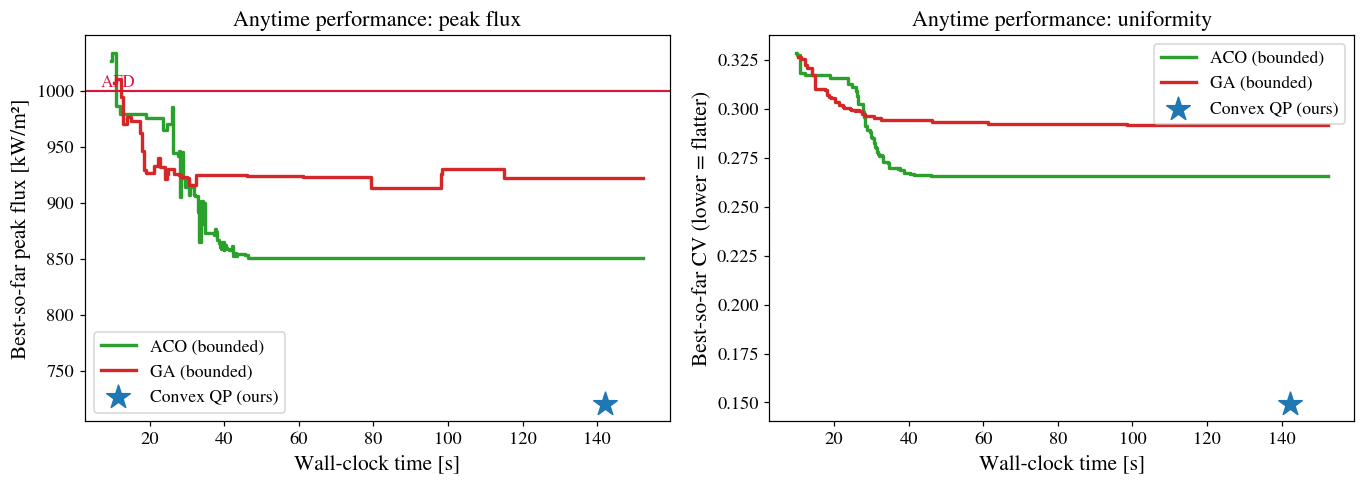

Reading: at the QP's own wall time (star), each baseline's best-so-far quality is the
fair equal-budget comparison; flat tails mean extra time stopped buying improvement.


In [13]:
# --- anytime performance: best-so-far quality vs wall-clock time (equal budget) ---
fig, (axp, axc) = plt.subplots(1, 2, figsize=(12.6, 4.6))
for name, traj, colr in [('ACO (bounded)', aco_traj, 'C2'), ('GA (bounded)', ga_traj, 'C3')]:
    if len(traj) == 0: continue
    tt = [t for t, _, _ in traj] + [max(aco_time, ga_time)]
    pk = [p for _, p, _ in traj]; pk = pk + [pk[-1]]
    cv = [c for _, _, c in traj]; cv = cv + [cv[-1]]
    axp.step(tt, pk, where='post', color=colr, lw=2.2, label=name)
    axc.step(tt, cv, where='post', color=colr, lw=2.2, label=name)
axp.scatter([qp_time], [pk_qp], marker='*', s=260, color='C0', zorder=5, label='Convex QP (ours)')
axc.scatter([qp_time], [cv_qp], marker='*', s=260, color='C0', zorder=5, label='Convex QP (ours)')
pk_all = max([pk_qp] + [p for _, p, _ in aco_traj + ga_traj])
if F_max <= 1.3*pk_all:
    axp.axhline(F_max, color='crimson', lw=1.4)
    axp.text(0.02, F_max, ' AFD', color='crimson', va='bottom', fontsize=11,
             transform=axp.get_yaxis_transform())
axp.set_xlabel('Wall-clock time [s]'); axc.set_xlabel('Wall-clock time [s]')
axp.set_ylabel('Best-so-far peak flux [kW/m²]'); axc.set_ylabel('Best-so-far CV (lower = flatter)')
axp.set_title('Anytime performance: peak flux'); axc.set_title('Anytime performance: uniformity')
axp.legend(); axc.legend()
fig.tight_layout(); plt.savefig('fig13_anytime.png', dpi=600, bbox_inches='tight'); plt.show()
print("Reading: at the QP's own wall time (star), each baseline's best-so-far quality is the")
print("fair equal-budget comparison; flat tails mean extra time stopped buying improvement.")

## 10. Comparison — peak flux, uniformity, interception, compute time

Evaluates all methods against the same worst-case structural misalignment and reports
four quantities: peak flux versus the AFD, uniformity (CV, lower is flatter),
**interception efficiency** `η_int` — the fraction of the power delivered by the field
that actually lands on the receiver — and wall-clock time. A manuscript-ready LaTeX
version of the table is written to `table_comparison.tex`.

Interception is the energy-side counterpart to the flux metrics, and it is what makes
the trade-off explicit: flattening the profile pushes aim points toward the receiver
edges, which reduces the peak but increases spillage. Reporting peak flux without
interception would show only half of the exchange (cf. Besarati et al. 2014, who
report the same trade-off on a flat receiver). The balance is tunable rather than
fixed — through the reference profile `F_ref` and the per-heliostat spillage margin
`aim_margin_sigma`.

> **Reading the timing column fairly.** The QP optimizes all `2K` continuous
> corrections (5,300 variables at full field) to a certified optimum, whereas ACO and
> GA search `aco_groups × aco_grid²` discrete candidates (120 × 25 by default) — a far
> smaller and coarser space — and their reported times include the shared contribution
> tensor. All of these are design-time (offline) computations for a quasi-static
> drift, not real-time control loops. Within the QP, `qp_tol`, `cap_prune` and
> `cap_stride` trade solve time against tolerance.

The four flux maps share one color scale, set by the largest peak (the uncorrected
case), so the panels are directly comparable; each panel's own peak is printed in its
title, and the AFD is marked on the colorbar.

plant=gemasolar, K=2650, F_max=1000 kW/m^2, field delivers 201.5 MW
method                    peak        CV  eta_int %  P_int MW   time [s]
------------------------------------------------------------------------
Nominal (aligned)        950.0    0.3059      90.12     181.6         --
No correction           1039.1    0.3488      89.03     179.4         --
Convex QP (ours)         720.5    0.1493      83.82     168.9      142.2
ACO (bounded)            850.8    0.2658      88.53     178.4      151.9
GA (bounded)             921.7    0.2919      88.04     177.4      152.3
LaTeX table written to table_comparison.tex


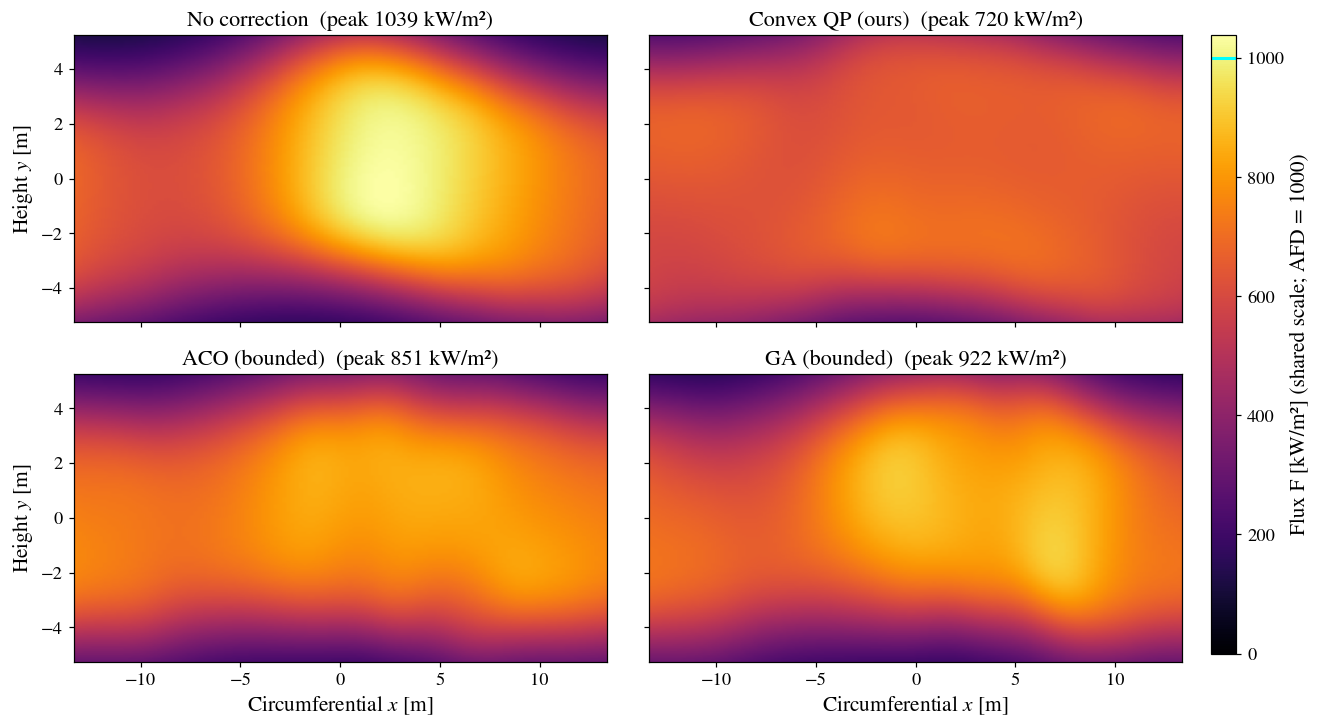

3-D comparison saved to fig10_comparison_3d.png (not displayed -- paper mode)


In [14]:
rows = [
    ("Nominal (aligned)",  F_nominal,   None),
    ("No correction",      F_perturbed, None),
    ("Convex QP (ours)",   F_qp_true,   qp_time),
    ("ACO (bounded)",      F_aco_true,  aco_time),
    ("GA (bounded)",       F_ga_true,   ga_time),
]
print(f"plant={CONFIG['plant']}, K={K}, F_max={F_max:.0f} kW/m^2, "
      f"field delivers {P_H.sum()/1e3:.1f} MW")
print(f"{'method':<20}{'peak':>10}{'CV':>10}{'eta_int %':>11}{'P_int MW':>10}{'time [s]':>11}")
print("-"*72)
for name, F, tm in rows:
    print(f"{name:<20}{F.max():>10.1f}{uniformity(F):>10.4f}{100*interception(F):>11.2f}"
          f"{F.sum()*pixel_area/1e3:>10.1f}{('--' if tm is None else f'{tm:.1f}'):>11}")

# manuscript-ready LaTeX version of the comparison table
with open('table_comparison.tex', 'w') as f:
    f.write("\\begin{tabular}{lccccc}\n\\toprule\n"
            "Method & Peak [kW/m$^2$] & CV [--] & $\\eta_{\\mathrm{int}}$ [\\%] & "
            "$P_{\\mathrm{int}}$ [MW] & Time [s] \\\\\n\\midrule\n")
    for name, F, tm in rows:
        f.write(f"{name} & {F.max():.1f} & {uniformity(F):.4f} & {100*interception(F):.2f} & "
                f"{F.sum()*pixel_area/1e3:.1f} & {'--' if tm is None else f'{tm:.1f}'} \\\\\n")
    f.write("\\bottomrule\n\\end{tabular}\n")
print("LaTeX table written to table_comparison.tex")

panels = [(F_perturbed, 'No correction'), (F_qp_true, 'Convex QP (ours)'),
          (F_aco_true, 'ACO (bounded)'),  (F_ga_true, 'GA (bounded)')]
vmax = max(F.max() for F, _ in panels)                              # shared scale

# ---- 2-D unwrapped comparison: THE manuscript figure (displayed), 2 x 2 for large panels ----
fig2, axs = plt.subplots(2, 2, figsize=(13.0, 7.4), sharex=True, sharey=True)
for ax2, (F, title) in zip(axs.ravel(), panels):
    im2 = ax2.imshow(F.reshape(n_v, n_h), extent=[-C_circ/2, C_circ/2, -H_rec/2, H_rec/2],
                     origin='lower', cmap='inferno', vmin=0, vmax=vmax, aspect='auto')
    ax2.set_title(title + f'  (peak {F.max():.0f} kW/m²)')
for ax2 in axs[1]: ax2.set_xlabel('Circumferential $x$ [m]')
for ax2 in axs[:, 0]: ax2.set_ylabel('Height $y$ [m]')
fig2.subplots_adjust(right=0.90, wspace=0.08, hspace=0.18)
cax2 = fig2.add_axes([0.92, 0.12, 0.018, 0.76])
cb2 = fig2.colorbar(im2, cax=cax2, label=f'Flux F [kW/m²] (shared scale; AFD = {F_max:.0f})')
if F_max <= vmax:
    cb2.ax.axhline(F_max, color='cyan', lw=2)
fig2.savefig('fig10_comparison.png', dpi=600, bbox_inches='tight'); plt.show()

# ---- 3-D comparison (saved for slides/appendix -- not displayed) ----
norm_c = mcolors.Normalize(vmin=0.0, vmax=float(vmax))
fig = plt.figure(figsize=(18, 5.0))
for i, (F, title) in enumerate(panels):
    ax = fig.add_subplot(1, 4, i + 1, projection='3d')
    draw_flux_cylinder(ax, F, norm_c)
    az = hot_azim_deg(F)
    ax.view_init(elev=14, azim=az)
    ax.set_box_aspect((1, 1, H_rec/D_rec))
    ax.set_axis_off()
    ax.set_title(title + chr(10) + f'peak {F.max():.0f} kW/m²' + chr(10)
                 + f'(view: hot-spot azimuth {az:.0f}°)', fontsize=11)
sm = cm.ScalarMappable(norm=norm_c, cmap='inferno'); sm.set_array([])
fig.colorbar(sm, ax=fig.axes, shrink=0.7, pad=0.015,
             label=f'Flux F [kW/m²] (shared scale; AFD = {F_max:.0f})')
fig.savefig('fig10_comparison_3d.png', dpi=600, bbox_inches='tight'); plt.close(fig)
print("3-D comparison saved to fig10_comparison_3d.png (not displayed -- paper mode)")

## 11. Phase-1 / Phase-2 decoupling (manuscript Sec. 4.2)

**Setup.** Phase 1 is the daily sun-tracking loop (e.g. a well-tuned PID); it leaves a
*transient* residual pointing error ε that varies from day to day. Phase 2 is the
**static** correction computed here for the *fixed* structural misalignment Δmech.
The correction `z_design` is computed **once, offline, at ε = 0** under the real AFD
cap, and stays deployed while the tracking loop runs. It is exactly the Sec. 8
solution — same aim points, same target, same cap — so it is reused rather than
re-solved.

**Question.** With `z_design` and Δmech held fixed, how does the *deployed* system
behave as the daily tracking residual grows? The sweep over ε/Δmech evaluates three
cases on the true nonlinear flux: **uncorrected** (nominal + Δmech + ε), **deployed**
(the same plus the fixed `z_design`), and an **oracle** (the QP re-solved with full
knowledge of ε). The oracle is the ceiling, and the deployed-to-oracle gap is the
price of *not* knowing ε — the formal measure of independence. Those re-solves
dominate this section's runtime, so only `CONFIG['ind_oracle_points']` sweep points
receive one; `CONFIG['ind_oracle'] = False` skips them entirely.

**Two tracking-error structures**, because their physics differ fundamentally:

- **Random** — independent per-heliostat directions (uncorrelated servo noise).
  Hundreds of independent shifts of overlapping Gaussians *self-average* (a 1/√K
  effect): the aggregate flux only blurs, leaving the deployed correction nearly
  unaffected. This is a genuine robustness property of correcting at field level.
- **Coherent** — one drift direction shared by the whole field (common-mode bias from
  the sun-position algorithm, time synchronization, or the refraction model). Nothing
  averages out, and the flux pattern moves off the aim points the QP certified. This
  is the binding case, and the Phase-1 specification is derived from it.

**Metrics.** CV, plus **peak flux against the AFD**: the QP's safety certificate holds
at the aim points it assumed, and ε moves those aim points, so the margin erodes
*continuously* rather than failing abruptly. ε is treated as a worst-instant snapshot,
which is conservative and consistent with an instantaneous flux limit; bands show
min–max over `CONFIG['ind_seeds']` draws. At large ε some beams partly spill off the
receiver — real physics, and the mean flux drops accordingly — which is why peak flux
is the robust safety metric in that regime.

deployed static correction (eps=0, reused from Sec. 8): CV=0.1493, peak=720.5 kW/m^2 (AFD 1000)


oracle: 4 QP re-solves in 488.9s


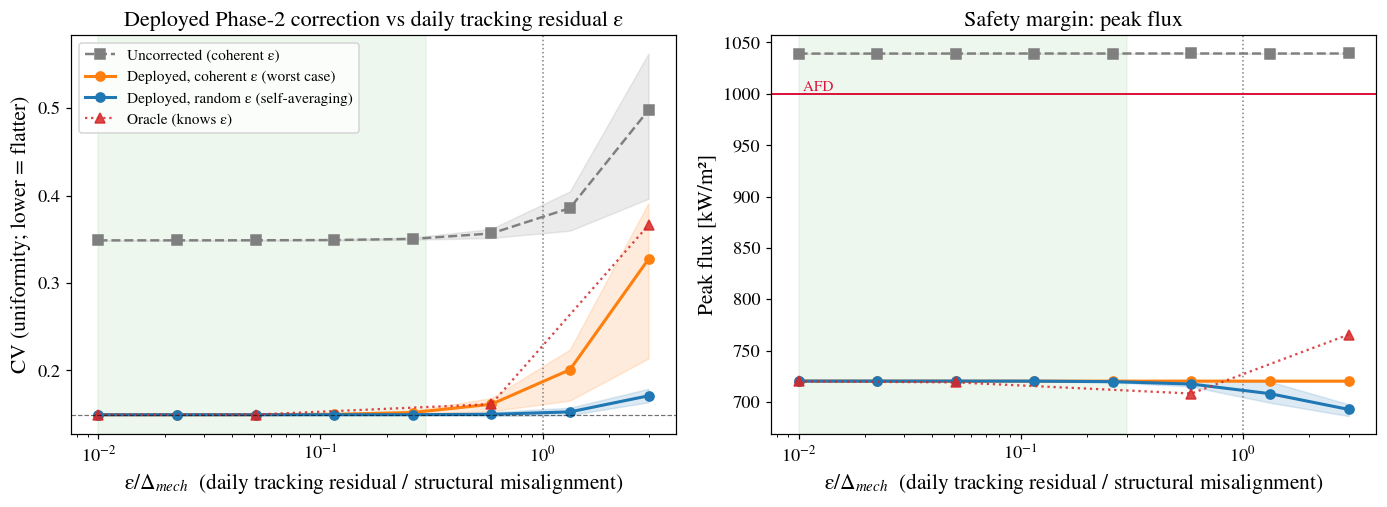

Phase-1 spec (coherent eps): residual must stay below 0.59 x Delta_mech = 0.59 m (~1.0-4.8 mrad) to keep the deployed correction within 10% of its design CV; beyond that the phases no longer decouple.
at eps = Delta_mech: coherent deployed CV 0.201 (uncorrected 0.386, benefit retained 78%); random deployed CV 0.153
at eps = 3.0 x Delta_mech: coherent deployed CV 0.327 (uncorrected 0.498, benefit retained 49%); random deployed CV 0.171
random per-heliostat eps self-averages (~1/sqrt(K)); the deployed correction is nearly immune to it -- a robustness property of field-level correction worth stating in the paper.


In [15]:
# --- the deployed static correction: designed ONCE for Delta_mech, with the real AFD cap ---
# The Sec. 8 QP already solved exactly this problem (same aims, target, cap) -- reuse it.
F_ref_d = F_ref
r_design = qp
assert r_design['dx'] is not None, f"design QP infeasible: {r_design['status']}"
zdx, zdy = r_design['dx'], r_design['dy']
CV_design, peak_design = uniformity(r_design['F_true']), r_design['peak']
print(f"deployed static correction (eps=0, reused from Sec. 8): CV={CV_design:.4f}, "
      f"peak={peak_design:.1f} kW/m^2 (AFD {F_max:.0f})")

ratios = np.logspace(np.log10(0.01), np.log10(3.0), CONFIG['ind_n_ratios'])
nS = CONFIG['ind_seeds']
res = {}   # res[(mode,'unc'/'dep')] -> (nS, n_ratios) CV and peak arrays
for mode in ('random', 'coherent'):
    cu = np.zeros((nS, ratios.size)); cd = np.zeros_like(cu)
    pu = np.zeros_like(cu);           pd = np.zeros_like(cu)
    for s in range(nS):
        rng_s = np.random.default_rng(100 + s)
        if mode == 'random':                      # independent per-heliostat directions
            ex = rng_s.standard_normal(K); ey = rng_s.standard_normal(K)
            nn = np.sqrt(ex**2 + ey**2); ex /= nn; ey /= nn
        else:                                     # one shared drift direction (common-mode)
            th_c = rng_s.uniform(0, 2*np.pi)
            ex = np.full(K, np.cos(th_c)); ey = np.full(K, np.sin(th_c))
        for j, ratio in enumerate(ratios):
            em = ratio*Dmech_mag
            xt, yt = x0_mis + em*ex, y0_mis + em*ey
            Fu = flux_map(xt, yt)
            Fd = flux_map(xt + zdx, yt + zdy)     # deployed static correction applied
            cu[s, j], cd[s, j] = uniformity(Fu), uniformity(Fd)
            pu[s, j], pd[s, j] = Fu.max(), Fd.max()
    res[(mode,'unc')] = (cu, pu); res[(mode,'dep')] = (cd, pd)

# oracle ceiling on the binding (coherent) case, one draw. The QP re-solves dominate this
# section's runtime, so only CONFIG['ind_oracle_points'] sweep points get one.
CV_orc = np.full(ratios.size, np.nan); PK_orc = np.full(ratios.size, np.nan)
if CONFIG['ind_oracle']:
    n_orc = int(min(CONFIG['ind_oracle_points'], ratios.size))
    orc_idx = np.unique(np.round(np.linspace(0, ratios.size - 1, n_orc)).astype(int))
    rng_s = np.random.default_rng(100); th_c = rng_s.uniform(0, 2*np.pi)
    ex = np.full(K, np.cos(th_c)); ey = np.full(K, np.sin(th_c))
    t_orc = time.time()
    for j in orc_idx:
        em = ratios[j]*Dmech_mag
        r_o = solve_qp(x0_mis + em*ex, y0_mis + em*ey, F_ref_d, F_max)
        if r_o['dx'] is not None:
            CV_orc[j], PK_orc[j] = uniformity(r_o['F_true']), r_o['peak']
    print(f"oracle: {orc_idx.size} QP re-solves in {time.time()-t_orc:.1f}s")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.8, 4.8))
def band(ax, Y, color, ls, lab, lw=1.6):
    ax.semilogx(ratios, Y.mean(0), ls, color=color, lw=lw, label=lab)
    ax.fill_between(ratios, Y.min(0), Y.max(0), color=color, alpha=0.15)
for ax, which in [(ax1, 0), (ax2, 1)]:
    ax.axvspan(ratios[0], 0.3, color='C2', alpha=0.08)
    ax.axvline(1.0, color='grey', ls=':', lw=1)
    band(ax, res[('coherent','unc')][which], 'C7', 's--', 'Uncorrected (coherent ε)')
    band(ax, res[('coherent','dep')][which], 'C1', 'o-', 'Deployed, coherent ε (worst case)', lw=2)
    band(ax, res[('random','dep')][which],   'C0', 'o-', 'Deployed, random ε (self-averaging)', lw=2)
    Yo = CV_orc if which == 0 else PK_orc
    fin = np.isfinite(Yo)
    if fin.any():
        ax.semilogx(ratios[fin], Yo[fin], '^:', color='C3', alpha=0.85, label='Oracle (knows ε)')
    ax.set_xlabel('ε/Δ$_{mech}$  (daily tracking residual / structural misalignment)')
ax1.set_ylabel('CV (uniformity; lower = flatter)')
ax2.set_ylabel('Peak flux [kW/m²]')
ax1.axhline(CV_design, color='k', ls='--', lw=0.8, alpha=0.55)
pk_all = max(res[('coherent','unc')][1].max(), res[('coherent','dep')][1].max())
if F_max <= 1.15*pk_all:
    ax2.axhline(F_max, color='crimson', lw=1.3)
    ax2.text(ratios[0], F_max, ' AFD', color='crimson', va='bottom', fontsize=10)
ax1.legend(fontsize=10, loc='upper left')
ax1.set_title('Deployed Phase-2 correction vs daily tracking residual ε')
ax2.set_title('Safety margin: peak flux')
fig.tight_layout(); plt.savefig('fig11_independence.png', dpi=600, bbox_inches='tight'); plt.show()

# --- data-driven summary; the Phase-1 spec comes from the COHERENT (binding) case ---
dep_c = res[('coherent','dep')][0].mean(0); unc_c = res[('coherent','unc')][0].mean(0)
dep_r = res[('random','dep')][0].mean(0)
ok = ratios[dep_c <= 1.10*CV_design]
if ok.size and ok.max() < ratios[-1]:
    eps_m = ok.max()*Dmech_mag; ang = np.arctan(eps_m/D)
    print(f"Phase-1 spec (coherent eps): residual must stay below {ok.max():.2f} x Delta_mech "
          f"= {eps_m:.2f} m (~{ang.min()*1e3:.1f}-{ang.max()*1e3:.1f} mrad) to keep the deployed "
          f"correction within 10% of its design CV; beyond that the phases no longer decouple.")
elif ok.size:
    print(f"coherent eps: deployed CV stays within 10% of design over the whole sweep "
          f"(up to {ratios[-1]:.1f} x Delta_mech = {ratios[-1]*Dmech_mag:.2f} m).")
for j, tag in [(int(np.argmin(np.abs(ratios-1.0))), 'eps = Delta_mech'), (len(ratios)-1, f'eps = {ratios[-1]:.1f} x Delta_mech')]:
    ret = (unc_c[j]-dep_c[j])/max(unc_c[j]-CV_design, 1e-12)
    print(f"at {tag}: coherent deployed CV {dep_c[j]:.3f} (uncorrected {unc_c[j]:.3f}, "
          f"benefit retained {100*ret:.0f}%); random deployed CV {dep_r[j]:.3f}")
print(f"random per-heliostat eps self-averages (~1/sqrt(K)); the deployed correction is nearly "
      f"immune to it -- a robustness property of field-level correction worth stating in the paper.")

## Modeling assumptions and limitations

The results above depend on modeling choices that the source publications do not
fully pin down. They are collected here so that they can be checked, changed, or
challenged; each is a `CONFIG` knob unless noted otherwise.

**Plant and operating point**

1. **Field reconstruction.** Exact as-built heliostat coordinates for Gemasolar are
   proprietary, so the field is a representative radial-staggered ring reconstruction
   with the correct heliostat count, mirror area, radial extent and tower height.
   Absolute flux values therefore carry the uncertainty of that reconstruction; the
   *comparison* between methods, which all run on the identical field, does not.
2. **Single design point.** Everything is evaluated at spring-equinox solar noon, the
   customary reference condition in this literature. Annual or seasonal performance
   would require sweeping the design point, which changes both the incident power and
   the beam-spread distribution across the field.
3. **Optical error budget.** σ_slope = 2.6 mrad and σ_track = 2.1 mrad are the
   published Gemasolar-class values; `σ_bq = 2σ_slope` follows the HFLCAL definition.
   Beam spread is quadratic in these terms, so they propagate directly to peak flux.

**Correction problem**

4. **Misalignment magnitude and model.** Δmech = 1.0 m per heliostat (≈ 0.8–4.1 mrad
   of mirror tilt over this field) represents the worst-case end of a post-calibration
   residual, applied in the convergent worst-case pattern. `CONFIG['mis_model']`
   switches between a constant residual *displacement* (default) and a constant
   residual *angle*, in which displacement grows with slant range as in the literal
   form of Eq. (6). The choice changes which part of the field dominates the hot spot.
5. **Correction bound.** `delta_max = ±1 m` on both axes. It is validated feasible at
   full field scale, and equals the assumed residual, so the box is in principle able
   to cancel Δmech entirely. A tighter bound restricts the achievable flattening; a
   looser one eventually leaves the region where the first-order model is accurate.
6. **Nominal aiming strategy.** The default `aimfactor` scheme is an AFD-feasible
   aiming-factor strategy tuned so the aligned plant peaks at 95 % of the AFD
   (`nominal_peak_target`). Simpler `center`, `vertical` and `spread` schemes are also
   available. The nominal aiming is taken as *given*, upstream of the correction
   problem; matching a specific plant's documented strategy would change the starting
   point of the comparison.
7. **Uniform reference profile.** `F_ref` is flat at the mean intercepted level, which
   makes maximum flattening the objective and sets the interception cost reported in
   Sec. 10. A non-uniform `F_ref` — for instance one shaped by the receiver's tube
   circuit or a lower target — trades uniformity against interception differently.

**Physics deliberately excluded**

8. **Blocking and shadowing** between heliostats are neglected (`f_bs = 1`), customary
   at the fidelity level of aiming studies but an optimistic bias on absolute power.
9. **Footprint curvature.** HFLCAL places one 2-D Gaussian on the unwrapped surface
   and ignores distortion of the footprint by the cylinder's curvature.
10. **No receiver thermal model.** The AFD enters as a single scalar limit, uniform
    over the surface. Real allowable flux densities vary over the receiver with the
    salt temperature and mass flow along each circuit, so a coupled thermal model
    would make the limit position-dependent — and, being tighter in places, would bind
    differently.

**Scope of the comparison**

11. **Grouped baselines.** ACO and GA search 120 groups × 25 candidate offsets, the
    standard scaling device at this field size, while the QP optimizes all 5,300
    variables continuously. The equal-budget protocol equalizes *compute time*, not
    decision-space richness; grouping is intrinsic to how these methods scale here,
    but a finer discretization with far more time would narrow the uniformity gap.
12. **Wall-clock budgeting.** Because the baselines are time-budgeted, their reported
    numbers depend on machine speed, whereas the QP result does not.